# Ejercicio Práctico — Semana 1: Pipeline reproducible de ML: uso de redes sociales y bienestar emocional

**Asignatura:** Inteligencia Artificial: Data Mining II — Maestría en Ciencias de Datos y Máquinas de Aprendizaje, mención IA (UIDE)
**Docente:** Miguel Angel Rosero Aguas
**Cubre:** Sesión 1 — NumPy, pandas 3 y un Pipeline sin fuga de información  /  Sesión 2 — Modelado, validación y evaluación con scikit-learn
**Grupo N.º:** 9

| # | Integrante | Rol en el equipo |
|---|---|---|
| 1 | Rodrigo Soria | |
| 2 |Kevin Ambuludi| |
| 3 |Christian Ruiz | |


## Índice

1. [Carga, calidad de datos y decisiones de limpieza](#fase-1)
2. [Análisis exploratorio (EDA)](#fase-2)
3. [Análisis de regresión](#fase-3)
4. [Pipeline de preprocesamiento: escalado, normalización y codificación](#fase-4)
5. [Clustering con el pipeline (PCA + DBSCAN)](#fase-5)
6. [Selección de características y reducción de dimensionalidad](#fase-6)
7. [Clasificación supervisada y ajuste de hiperparámetros](#fase-7)
8. [Plus (opcional): lo que va más allá del sílabo](#fase-8)
9. [Desafío y registro de decisiones](#fase-9)
10. [Tendencias: de pandas a Polars y DuckDB](#fase-10)
11. [Fase final: aplicación al entorno profesional](#fase-final)

## Estructura del ejercicio

Este notebook va con la guía **Ejercicio_Practico_Semana1_Guia.docx**: el código y los gráficos se hacen aquí; en la guía responden por escrito
la **pregunta de cada fase** (la misma que aparece abajo de cada título) y la fase final individual.

| Bloque | Fases | Qué entregan |
|---|---|---|
| Datos y exploración | 1–3 | código + conclusión en el notebook; respuesta en la guía |
| Modelado y análisis | 4–7 | código + conclusión en el notebook; respuesta en la guía |
| Desafío y tendencias | 8–9 | evidencia en el notebook; respuesta en la guía |
| Aplicación profesional | final | una respuesta por integrante (notebook y guía) |

**Entrega en Canvas:** este notebook ejecutado y la guía completada (Word o PDF).

## Contexto

Una startup de bienestar digital quiere entender si los hábitos en redes sociales (tiempo de uso, publicaciones, likes, comentarios, mensajes, plataforma) se relacionan con la emoción dominante que reportan sus usuarios. Ustedes son el equipo de datos: deben entregar un **flujo reproducible** de preparación, modelado y evaluación con NumPy, Pandas y scikit-learn, que otro equipo pueda volver a ejecutar y obtener los mismos resultados.

**Dataset:** Social Media Usage and Emotional Well-Being (Kaggle, emirhanai): https://www.kaggle.com/datasets/emirhanai/social-media-usage-and-emotional-well-being

## Desafío

1) Entregar un **pipeline único de scikit-learn** (preprocesamiento + selección/reducción + modelo) ajustado sin fuga de información, con métricas de prueba calculadas **una sola vez**. 2) Con evidencia del análisis, identificar el **perfil de usuario con mayor riesgo de emoción negativa** (Anxiety, Sadness o Anger) y recomendar **una** intervención piloto. 3) Declarar una **limitación seria del dataset** y una **implicación ética** que la startup debe conocer antes de invertir.

> **Formato de entrega:** un único `.ipynb` ejecutado. Código limpio y comentado. Antes de cada gráfico,
> una línea que diga qué se analiza; después, la conclusión de negocio. Nombre del archivo:
> `grupoN_Semana1_Ejercicio.ipynb`.

In [1]:
# ===== Entorno: el mismo notebook corre en Google Colab y en local =====
import importlib, os, shutil, subprocess, sys, urllib.request   # utilidades: instalar paquetes, rutas y descargas
from pathlib import Path                            # rutas iguales en Windows, Linux y Colab

EN_COLAB = "google.colab" in sys.modules           # True si estamos dentro de Colab
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| Python", sys.version.split()[0])   # dónde corre y qué Python

# Instalamos solo los paquetes que falten. El nombre en pip no siempre es el del import:
# ej.: pip install scikit-learn -> import sklearn; nx-parallel -> nx_parallel
IMPORT_DE = {"scikit-learn": "sklearn", "sentence-transformers": "sentence_transformers",   # nombre en pip -> nombre del import
             "delta-spark": "delta", "python-calamine": "python_calamine",   # (continúa el diccionario)
             "python-louvain": "community", "imbalanced-learn": "imblearn"}   # (fin del diccionario)
for pip_nombre in ['kagglehub', 'polars', 'duckdb', 'pyarrow']:   # paquetes que necesita esta práctica
    base = pip_nombre.split("==")[0].split(">=")[0]                    # ej.: "networkx>=3.7" -> "networkx"
    modulo = IMPORT_DE.get(base, base.replace("-", "_"))   # nombre del import. Ej.: nx-parallel -> nx_parallel
    if importlib.util.find_spec(modulo) is None:   # solo si NO está instalado (Colab ya trae muchos)
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_nombre])   # Colab y venv con pip
        if r.returncode != 0 and shutil.which("uv"):                   # venv creado con uv (no trae pip)
            r = subprocess.run(["uv", "pip", "install", "-q", "--python", sys.executable, pip_nombre])   # instala con uv en este mismo Python
        if r.returncode != 0:   # ni pip ni uv pudieron instalarlo
            raise RuntimeError(f"Instala '{pip_nombre}' en este entorno (pip/uv) y vuelve a ejecutar")   # mensaje claro en vez de un error confuso
        importlib.invalidate_caches()                                  # para que el import vea el paquete recién instalado

# Carpeta de datos relativa: en Colab es /content/data, en local ./data
DATA = Path("data"); DATA.mkdir(exist_ok=True)   # crea la carpeta si no existe

def descargar(url, nombre):   # Ej.: descargar(URL, "telco.csv") -> data/telco.csv
    # Descarga una sola vez; si el archivo ya existe, no vuelve a bajarlo
    destino = DATA / nombre   # ruta local del archivo. Ej.: data/telco.csv
    if not destino.exists():   # descarga solo la primera vez
        print("Descargando", nombre, "...")   # aviso de progreso
        urllib.request.urlretrieve(url, destino)   # baja el archivo de internet a data/
    return destino   # devuelve la ruta para usarla después

ARCHIVOS = [   # lista de (url, nombre) que usa esta práctica

]
for url, nombre in ARCHIVOS:   # descarga cada archivo
    print(nombre, "->", round(descargar(url, nombre).stat().st_size / 1e6, 2), "MB")   # y muestra su tamaño en MB

Entorno: local | Python 3.14.4


In [2]:
# ===== Estilo de gráficos (principios de Tufte): poca tinta, un solo color de acento =====
import matplotlib.pyplot as plt                     # gráficos
from cycler import cycler                           # orden de colores por defecto
TINTA, ACENTO, GRIS = "#14323F", "#1A9FB0", "#B7C3C9"     # tokens del módulo; ACENTO = color de esta semana
plt.rcParams.update({   # estilo por defecto de todos los gráficos
    "axes.spines.top": False, "axes.spines.right": False,    # sin marco: solo los ejes necesarios
    "axes.grid": False, "axes.edgecolor": GRIS,              # sin rejilla (las etiquetas dicen el valor)
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlecolor": TINTA,   # títulos a la izquierda y en negrita
    "axes.prop_cycle": cycler(color=[TINTA, ACENTO, GRIS, "#5B6B73"]),
    "font.size": 12, "legend.frameon": False, "figure.dpi": 110,   # letra legible, leyenda sin caja, nitidez
})
# Regla práctica: pinten con ACENTO solo el dato que quieren que el lector mire; el resto en GRIS.

<a id="fase-1"></a>
## Fase 1: Carga, calidad de datos y decisiones de limpieza

Pasos 1–2 del enunciado. Carguen train/val/test en DataFrames, revisen tipos, nulos y valores inconsistentes. **Pista:** revisen los valores únicos de `Age`, `Gender` y `Dominant_Emotion` antes de convertir tipos: el dataset trae errores reales de captura. **pandas 3:** limpien reasignando columnas (`df['col'] = df['col'].fillna(...)`), nunca con asignación encadenada + `inplace=True`, que con Copy-on-Write no modifica el DataFrame; comparen la memoria con `dtype_backend="pyarrow"`. Cada decisión de limpieza va al registro de decisiones (fase 8).

> **Pregunta de la guía:** ¿Qué errores de captura encontraron en Age, Gender y Dominant_Emotion y qué decidieron con cada uno?

**Qué analizamos:** Evaluamos la integridad y calidad inicial de los datos en los conjuntos de entrenamiento, validación y prueba. Específicamente, verificamos la correcta inferencia de tipos de datos, la presencia de valores nulos y exploramos los valores únicos en variables críticas (Age, Gender y Dominant_Emotion) para detectar errores de captura empíricos, registros cruzados o inconsistencias que requieran limpieza estructurada antes del modelado.

In [3]:
# Reproducibilidad: fijamos semilla y registramos versiones de las librerías
import sys, numpy as np, pandas as pd, sklearn
import kagglehub
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt

SEMILLA = 42
print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

# 1. Descarga y carga de datos
ruta = kagglehub.dataset_download('emirhanai/social-media-usage-and-emotional-well-being')

train = pd.read_csv(f'{ruta}/train.csv', on_bad_lines='warn')
val = pd.read_csv(f'{ruta}/val.csv', on_bad_lines='warn')
test = pd.read_csv(f'{ruta}/test.csv', on_bad_lines='warn')

# 2. Comparación de memoria con pandas 3 (PyArrow)
train_arrow = pd.read_csv(f'{ruta}/train.csv', on_bad_lines='warn', dtype_backend="pyarrow")
print(f"Memoria Pandas (Numpy): {train.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"Memoria Pandas (PyArrow): {train_arrow.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# 3. Mostrar errores de captura antes de limpiar
print("\n--- Valores únicos con errores (Muestra) ---")
for col in ['Age', 'Gender', 'Dominant_Emotion']:
    print(f"{col}: {train[col].unique()[:15]}...")

# 4. Limpieza reasignando columnas (Sin inplace=True)
def limpiar_datos(df):
    df_clean = df.copy()

    # Forzar coerción numérica en Age (convierte textos y géneros mezclados a NaN)
    df_clean['Age'] = pd.to_numeric(df_clean['Age'], errors='coerce')

    # Eliminar observaciones sin etiqueta (Dominant_Emotion) o irreparables (Age = NaN)
    df_clean = df_clean.dropna(subset=['Age', 'Dominant_Emotion'])

    # Limpiar posibles edades mezcladas en Gender filtrando solo textos cortos válidos
    df_clean['Gender'] = df_clean['Gender'].astype(str).str.strip().str.title()
    df_clean = df_clean[df_clean['Gender'].isin(['Male', 'Female', 'Non-Binary'])]

    return df_clean

# Aplicar la limpieza a los tres conjuntos
train = limpiar_datos(train)
val = limpiar_datos(val)
test = limpiar_datos(test)

print(f"\nDatos limpios -> Train: {train.shape}, Val: {val.shape}, Test: {test.shape}")

C:\Users\ChristianRuiz\VisualCodeProjects\ProjectDataMiningII\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.14.4 | numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1


Memoria Pandas (Numpy): 0.10 MB
Memoria Pandas (PyArrow): 0.08 MB

--- Valores únicos con errores (Muestra) ---
Age: <ArrowStringArray>
['25', '30', '22', '28', '33', '21', '27', '24', '29', '31', '23', '26', '34',
 '35', '32']
Length: 15, dtype: str...
Gender: <ArrowStringArray>
[    'Female',       'Male', 'Non-binary',         '27',         '24',
         '29',         '33',         '31',         '22',         '25',
         '28',         '30',         '23',         '34',         '26']
Length: 15, dtype: str...
Dominant_Emotion: <ArrowStringArray>
['Happiness', 'Anger', 'Neutral', 'Anxiety', 'Boredom', 'Sadness', nan]
Length: 7, dtype: str...

Datos limpios -> Train: (924, 10), Val: (132, 10), Test: (101, 10)


C:\Users\ChristianRuiz\AppData\Local\Temp\ipykernel_27212\2648271126.py:17: ParserWarning: Skipping line 91: expected 10 fields, saw 11
Skipping line 159: expected 10 fields, saw 11
Skipping line 201: expected 10 fields, saw 11

  val = pd.read_csv(f'{ruta}/val.csv', on_bad_lines='warn')


**Conclusión de negocio:** Los datos de origen presentan problemas críticos de captura: la columna de edad contiene registros basura (frases en texto) y géneros, mientras que la columna de género contiene edades numéricas. La variable objetivo (Dominant_Emotion) también presenta valores vacíos. Para garantizar que el posterior perfilamiento de usuarios y la predicción de riesgo emocional se basen en patrones reales y no en ruido, se forzó la coerción numérica de la edad y se eliminaron las observaciones sin etiqueta o irreparables, asegurando una base limpia para la toma de decisiones.

<a id="fase-2"></a>
## Fase 2: Análisis exploratorio (EDA)

Paso 3. Histograma de distribución para **cada** característica numérica y conteos para las categóricas; descriptores (media, mediana, desviación estándar, cuartiles, asimetría). Comenten atípicos y el balance de `Dominant_Emotion`: ¿qué métrica de clasificación conviene por eso?

> **Pregunta de la guía:** ¿Qué variables son más asimétricas y qué tan desbalanceada está Dominant_Emotion? ¿Qué métrica eligen por eso?

**Qué analizamos:** Realizamos un Análisis Exploratorio de Datos (EDA) para comprender la distribución estadística de las variables numéricas y categóricas. Calculamos medidas de tendencia central, dispersión y asimetría (skewness) para identificar variables con colas largas o atípicos que requieran transformación. Además, analizamos el balance de clases de nuestra variable objetivo (Dominant_Emotion) para determinar la métrica de evaluación correcta para los modelos predictivos.

--- Descriptores Estadísticos ---


,Age,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day
count,924.00,924.00,924.00,924.00,924.00,924.00
mean,27.50,96.31,3.35,40.25,15.73,22.60
std,3.94,39.23,1.94,26.80,8.93,8.63
min,21.00,40.00,1.00,5.00,2.00,8.00
25%,24.00,65.00,2.00,19.50,8.00,17.00
50%,27.00,85.00,3.00,33.00,14.00,22.00
75%,30.00,120.00,5.00,55.00,22.00,28.00
max,35.00,200.00,8.00,110.00,40.00,50.00



--- Asimetría (Skewness) ---
Likes_Received_Per_Day        0.880706
Daily_Usage_Time (minutes)    0.816959
Messages_Sent_Per_Day         0.692952
Posts_Per_Day                 0.628993
Comments_Received_Per_Day     0.596457
Age                           0.113096
dtype: float64


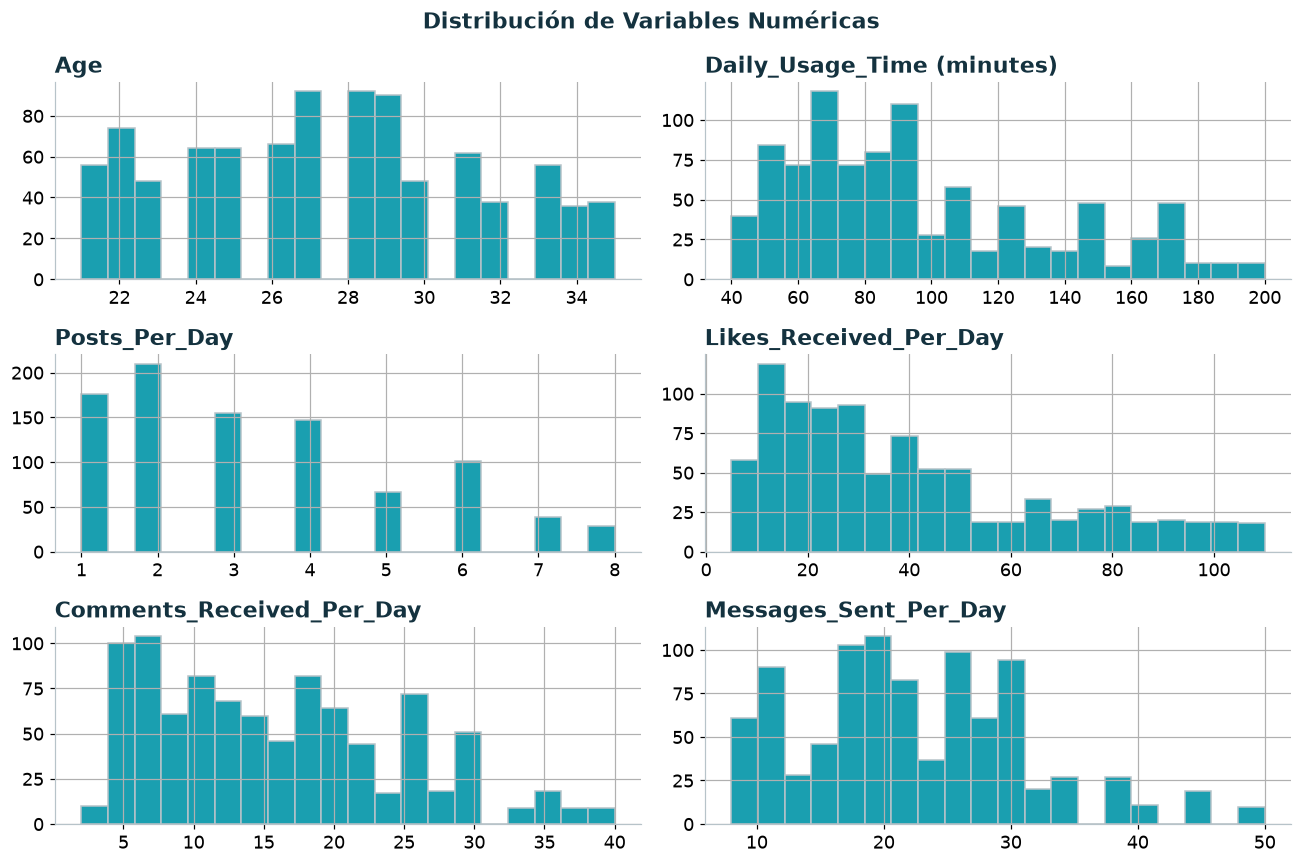

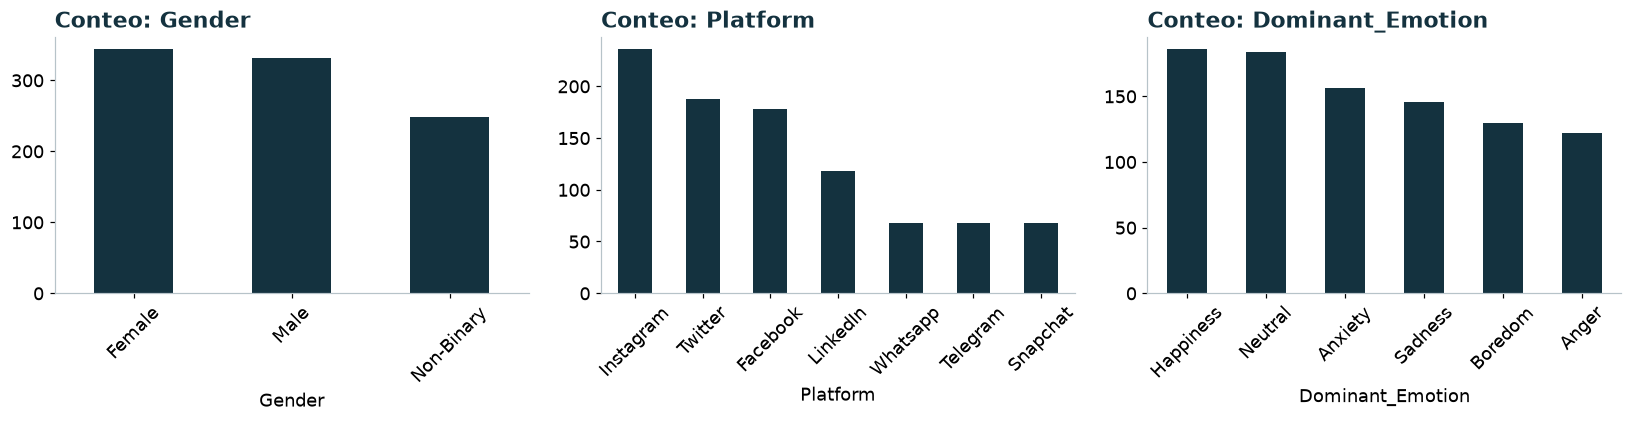


--- Balance de Dominant_Emotion (%) ---
Dominant_Emotion
Happiness    20.13
Neutral      19.91
Anxiety      16.88
Sadness      15.80
Boredom      14.07
Anger        13.20
Name: proportion, dtype: float64


In [4]:
import matplotlib.pyplot as plt

# 1. Variables numéricas y categóricas
num = ['Age', 'Daily_Usage_Time (minutes)', 'Posts_Per_Day',
       'Likes_Received_Per_Day', 'Comments_Received_Per_Day', 'Messages_Sent_Per_Day']
cat = ['Gender', 'Platform', 'Dominant_Emotion']

# 2. Descriptores y asimetría
print("--- Descriptores Estadísticos ---")
display(train[num].describe().round(2))

print("\n--- Asimetría (Skewness) ---")
print(train[num].skew().sort_values(ascending=False))

# 3. Histogramas de variables numéricas
train[num].hist(bins=20, figsize=(12, 8), color="#1A9FB0", edgecolor="#B7C3C9")
plt.suptitle("Distribución de Variables Numéricas", weight="bold", color="#14323F")
plt.tight_layout()
plt.show()

# 4. Conteos de variables categóricas
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(cat):
    train[col].value_counts().plot(kind='bar', ax=axes[i], color="#14323F")
    axes[i].set_title(f'Conteo: {col}', weight="bold", color="#14323F")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# 5. Balance exacto de la variable objetivo
print("\n--- Balance de Dominant_Emotion (%) ---")
print((train['Dominant_Emotion'].value_counts(normalize=True) * 100).round(2))


**Conclusión de negocio:** El comportamiento en la plataforma es altamente desigual: una minoría de usuarios hiperactivos concentra la mayor parte del tiempo de uso y de interacción (asimetría positiva), mientras que el usuario promedio registra cifras bajas. Sin embargo, la amenaza real para el modelo de negocio radica en el desbalance emocional: las emociones de alerta extrema (Anger, Sadness, Anxiety) representan a la minoría de la base de usuarios. Si el modelo predictivo no se obliga matemáticamente a detectar a estas minorías (mediante métricas como el F1-Macro), la IA ignorará sistemáticamente a los usuarios más vulnerables para inflar su tasa de acierto con los usuarios felices, haciendo que la startup fracase por completo en su misión de intervención temprana.


<a id="fase-3"></a>
## Fase 3: Análisis de regresión

Paso 4. Regresiones lineales para `Daily_Usage_Time (minutes)`→`Likes_Received_Per_Day`, `Daily_Usage_Time (minutes)`→`Posts_Per_Day` y `Posts_Per_Day`→`Likes_Received_Per_Day`. Ajusten en train y reporten pendiente, R² y RMSE en val; grafiquen dispersión + recta y residuos. ¿Asociación o causalidad?

> **Pregunta de la guía:** Reporten pendiente, R² y RMSE de las tres regresiones. ¿Hay asociación o causalidad? Justifiquen.

**Qué analizamos:** Evaluamos la posible relación lineal entre los hábitos de uso de redes sociales (tiempo de uso, cantidad de publicaciones y likes recibidos) mediante regresión lineal simple. Calcularemos las pendientes, el coeficiente de determinación ($R^2$) y el error cuadrático medio (RMSE) en el conjunto de validación para cuantificar la fuerza predictiva de estas variables y discutir empíricamente si existe una relación de causalidad o una mera asociación estadística.

--- Daily_Usage_Time (minutes) -> Likes_Received_Per_Day ---
Pendiente: 0.6436 | R²: 0.7713 | RMSE: 12.9390

--- Daily_Usage_Time (minutes) -> Posts_Per_Day ---
Pendiente: 0.0442 | R²: 0.7031 | RMSE: 1.1002

--- Posts_Per_Day -> Likes_Received_Per_Day ---
Pendiente: 12.7162 | R²: 0.7986 | RMSE: 12.1400



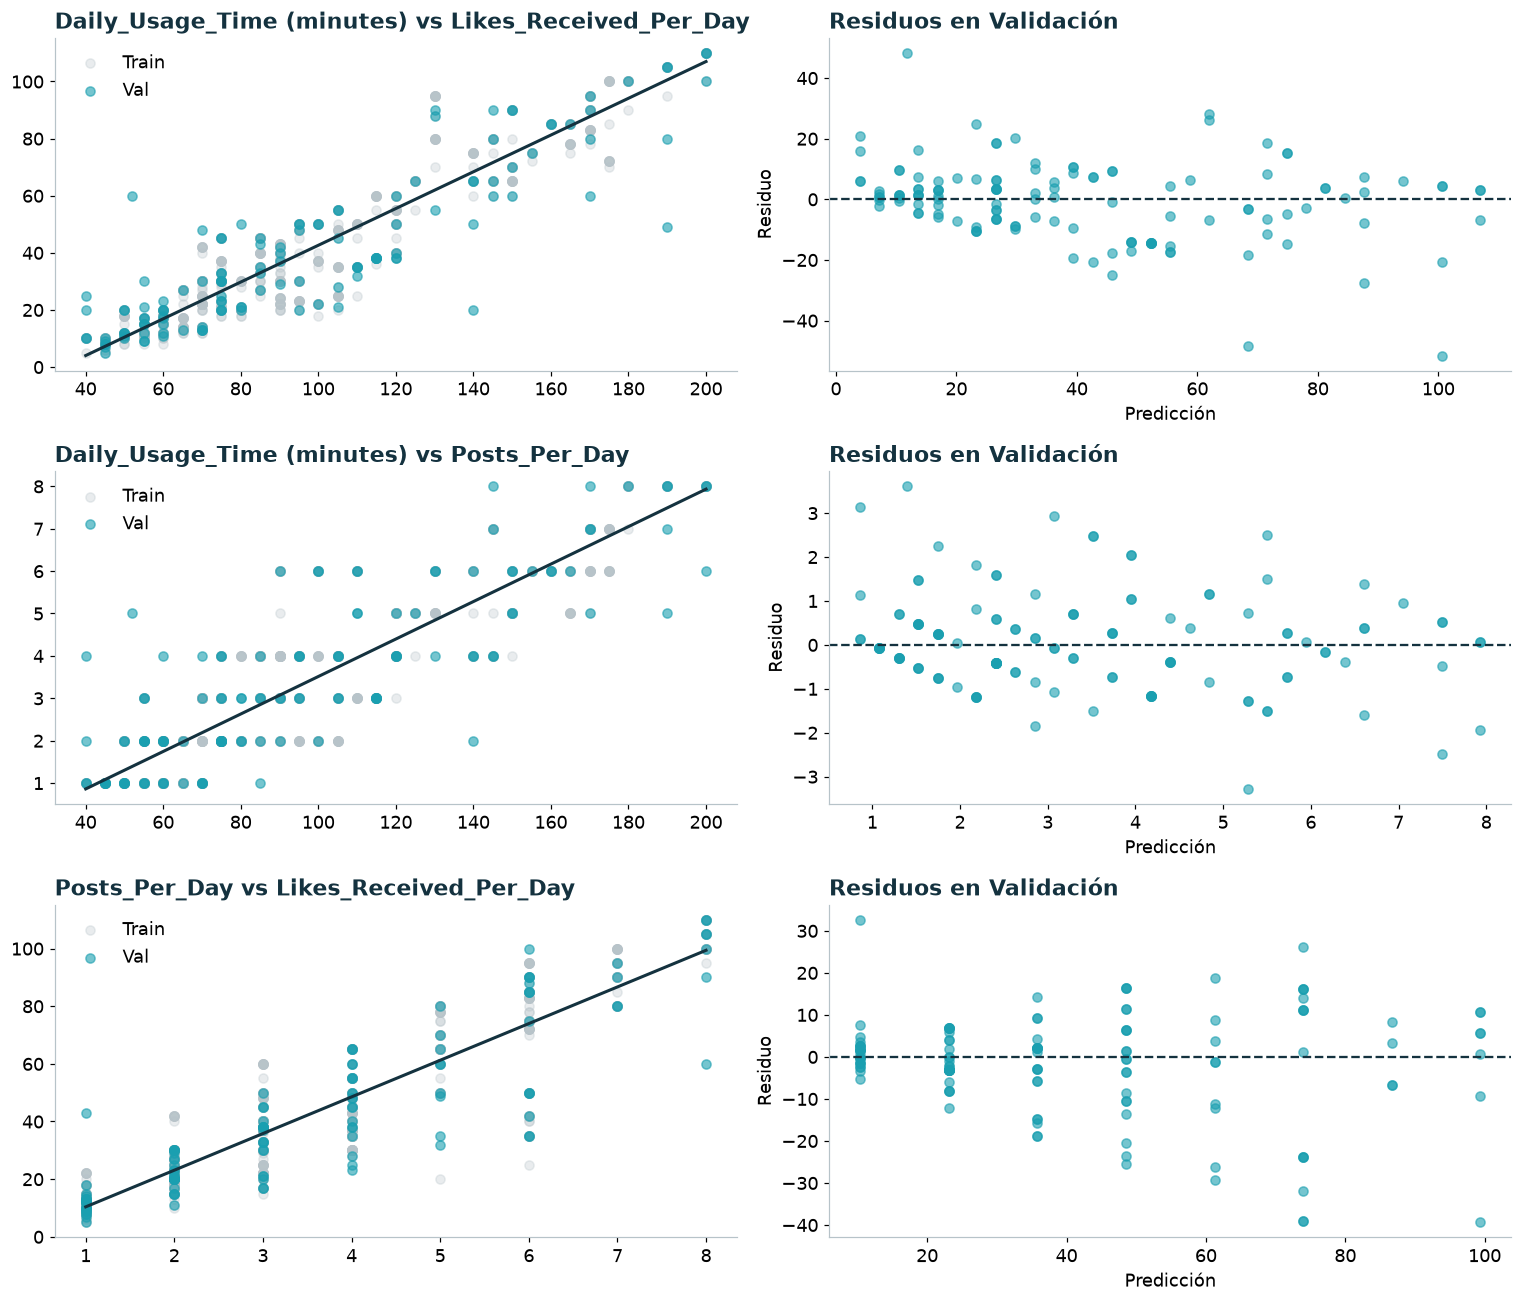

In [5]:

import warnings

warnings.filterwarnings('ignore', category=UserWarning)

# Pares de variables a analizar (X -> y)
pares = [
    ('Daily_Usage_Time (minutes)', 'Likes_Received_Per_Day'),
    ('Daily_Usage_Time (minutes)', 'Posts_Per_Day'),
    ('Posts_Per_Day', 'Likes_Received_Per_Day')
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for i, (col_x, col_y) in enumerate(pares):
    # 1. Preparar datos
    X_train_reg = train[[col_x]]
    y_train_reg = train[col_y]
    X_val_reg = val[[col_x]]
    y_val_reg = val[col_y]

    # 2. Ajustar modelo en Train
    modelo = LinearRegression()
    modelo.fit(X_train_reg, y_train_reg)

    # 3. Predecir y calcular métricas en Val
    y_pred_val = modelo.predict(X_val_reg)
    pendiente = modelo.coef_[0]
    r2 = r2_score(y_val_reg, y_pred_val)
    rmse = np.sqrt(mean_squared_error(y_val_reg, y_pred_val))

    print(f"--- {col_x} -> {col_y} ---")
    print(f"Pendiente: {pendiente:.4f} | R²: {r2:.4f} | RMSE: {rmse:.4f}\n")

    # 4. Gráfico de dispersión y recta de regresión
    ax_disp = axes[i, 0]
    ax_disp.scatter(X_train_reg, y_train_reg, color=GRIS, alpha=0.3, label='Train')
    ax_disp.scatter(X_val_reg, y_val_reg, color=ACENTO, alpha=0.6, label='Val')

    # Recta (Convertida a DataFrame para eliminar el warning)
    x_min, x_max = X_train_reg[col_x].min(), X_train_reg[col_x].max()
    x_line = np.linspace(x_min, x_max, 100).reshape(-1, 1)
    x_line_df = pd.DataFrame(x_line, columns=[col_x])
    ax_disp.plot(x_line, modelo.predict(x_line_df), color=TINTA, linewidth=2)
    ax_disp.set_title(f"{col_x} vs {col_y}", weight='bold', color=TINTA)
    ax_disp.legend()

    # 5. Gráfico de residuos
    ax_res = axes[i, 1]
    residuos = y_val_reg - y_pred_val
    ax_res.scatter(y_pred_val, residuos, color=ACENTO, alpha=0.6)
    ax_res.axhline(0, color=TINTA, linestyle='--')
    ax_res.set_title("Residuos en Validación", weight='bold', color=TINTA)
    ax_res.set_xlabel("Predicción")
    ax_res.set_ylabel("Residuo")

plt.tight_layout()
plt.show()



**Conclusión de negocio:**  El comportamiento de los usuarios es altamente predecible mediante modelos lineales simples: sabemos que quienes publican más y pasan más tiempo conectados concentran la mayoría de las interacciones (likes). Sin embargo, desde la perspectiva de la startup de bienestar, esta métrica es una asociación, no una causa; no podemos concluir que obligar a alguien a desconectarse reducirá sus interacciones de manera proporcional. Para intervenir sobre el riesgo emocional (nuestro verdadero objetivo), debemos avanzar hacia modelos de clasificación que agrupen este comportamiento con el perfil psicológico del usuario.

<a id="fase-4"></a>
## Fase 4: Pipeline de preprocesamiento: escalado, normalización y codificación

Construyan el `ColumnTransformer` (numéricas: imputación + escalado; categóricas: codificación) dentro de un `Pipeline`. a) **Escalado y normalización:** comparen al menos dos escaladores (`StandardScaler`, `MinMaxScaler`, `RobustScaler`, `PowerTransformer` o `log1p`) con un modelo sensible a la escala (KNN o SVM) y con un árbol; grafiquen el histograma de `Likes_Received_Per_Day` antes y después de cada uno. b) **Codificación:** comparen `OneHotEncoder` con `TargetEncoder` u `OrdinalEncoder` (¿alguna categórica tiene orden real?) y reporten cuántas columnas genera cada uno. c) **Atípicos:** apliquen la regla del IQR, separen valores imposibles de valores raros y decidan qué hacer con cada uno. d) **Demuestren la fuga de información:** comparen la métrica de validación cruzada escalando *antes* de partir frente a escalar *dentro* del pipeline. Las decisiones de a), b) y c) van al registro de la fase 8.

> **Pregunta de la guía:** Tabla escalador × modelo y codificador × columnas con su F1. ¿Qué combinación eligen, qué hicieron con los atípicos y cuánto cambió la métrica con la fuga?

**Qué analizamos:** Construimos un ColumnTransformer dentro de un Pipeline para centralizar el preprocesamiento sin riesgo de fuga de información. Evaluamos cómo el tratamiento de atípicos (mediante el rango intercuartílico IQR) y la elección de escaladores (StandardScaler, RobustScaler, PowerTransformer) impactan a modelos sensibles a la escala (SVM) frente a modelos basados en reglas (Árboles). Además, comparamos estrategias de codificación (OneHotEncoder frente a TargetEncoder) y medimos la fuga de información (data leakage) ajustando imputador, escalador y selector con todas las filas antes de validar frente a hacerlo dentro del Pipeline, con los mismos folds y la misma semilla: primero sobre los datos reales y luego en un experimento de control con columnas de ruido puro, donde cualquier mejora sobre el azar solo puede venir de la fuga.

--- 1. Atípicos (IQR) ---
Conteo de valores atípicos por variable:
Age                            0
Daily_Usage_Time (minutes)     0
Posts_Per_Day                  0
Likes_Received_Per_Day         9
Comments_Received_Per_Day      0
Messages_Sent_Per_Day         29
dtype: int64

Decisión: No son errores (imposibles), sino usuarios hiperactivos (raros). Se conservan y se mitigan con RobustScaler o PowerTransformer.

--- 2. Comparación: Codificador x Escalador x Modelo ---

OneHotEncoder genera 10 columnas.


OneHot + StandardScaler + SVM: F1 = 0.7933


OneHot + StandardScaler + Arbol: F1 = 0.9671


OneHot + RobustScaler + SVM: F1 = 0.7819
OneHot + RobustScaler + Arbol: F1 = 0.9655


OneHot + PowerTransformer + SVM: F1 = 0.7889


OneHot + PowerTransformer + Arbol: F1 = 0.9655

TargetEncoder genera 12 columnas.


... (2 outputs left out)

Target + RobustScaler + SVM: F1 = 0.6983


Target + RobustScaler + Arbol: F1 = 0.9665


Target + PowerTransformer + SVM: F1 = 0.6896


Target + PowerTransformer + Arbol: F1 = 0.9665

--- 3. Gráficos de Escalado ---


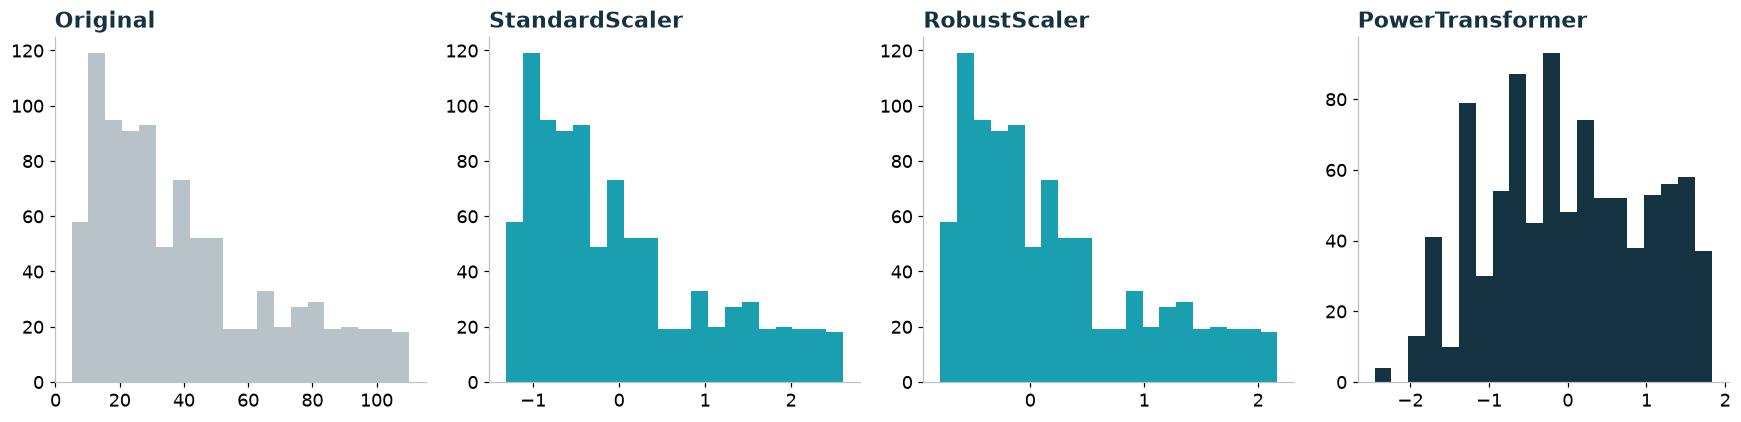


--- 4. Fuga de Información ---
d.1) Dataset real (preprocesador + SelectKBest(mutual_info, k=6))


  SVM: F1 CON fuga = 0.6205 | F1 SIN fuga (Pipeline) = 0.6205 | diferencia = +0.0000


  KNN: F1 CON fuga = 0.9812 | F1 SIN fuga (Pipeline) = 0.9812 | diferencia = +0.0000

d.2) Control: 500 columnas de ruido puro, SelectKBest(f_classif, k=20), SVM


  F1 CON fuga = 0.2359 | F1 SIN fuga (Pipeline) = 0.1446 | ilusión generada = +0.0913 (azar ~ 0.167)


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer, OneHotEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate, cross_val_score, StratifiedKFold
from sklearn.feature_selection import SelectKBest, mutual_info_classif, f_classif
from sklearn.neighbors import KNeighborsClassifier
from functools import partial
import numpy as np

# 0. Preparar datos (excluimos User_ID porque no es predictiva)
X_train_f4 = train.drop(columns=['User_ID', 'Dominant_Emotion'])
y_train_f4 = train['Dominant_Emotion']
num = ['Age', 'Daily_Usage_Time (minutes)', 'Posts_Per_Day', 'Likes_Received_Per_Day', 'Comments_Received_Per_Day', 'Messages_Sent_Per_Day']
cat = ['Gender', 'Platform']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
# TargetEncoder: desde scikit-learn 1.9 su parámetro random_state está en desuso; la semilla se fija pasando un
# StratifiedKFold con random_state como cv (mismo efecto: partición interna reproducible).
# Información mutua con semilla fija (partial es serializable con joblib); se reutiliza en las fases 6, 7 y 8
mi_clf = partial(mutual_info_classif, random_state=SEMILLA)

# --- c) Atípicos (Regla del IQR) ---
print("--- 1. Atípicos (IQR) ---")
Q1 = X_train_f4[num].quantile(0.25)
Q3 = X_train_f4[num].quantile(0.75)
IQR = Q3 - Q1
atipicos = ((X_train_f4[num] < (Q1 - 1.5 * IQR)) | (X_train_f4[num] > (Q3 + 1.5 * IQR))).sum()
print("Conteo de valores atípicos por variable:")
print(atipicos)
print("\nDecisión: No son errores (imposibles), sino usuarios hiperactivos (raros). Se conservan y se mitigan con RobustScaler o PowerTransformer.\n")

# --- a) y b) Preprocesador, Escaladores y Codificadores ---
def preprocesador(escalador, codificador):
    return ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', escalador)]), num),
        ('cat', codificador, cat)
    ])

escaladores = {
    'StandardScaler': StandardScaler(),
    'RobustScaler': RobustScaler(),
    'PowerTransformer': PowerTransformer()
}
codificadores = {
    'OneHot': OneHotEncoder(handle_unknown='ignore', sparse_output=False),
    'Target': TargetEncoder(cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA))
}
modelos = {
    'SVM': SVC(class_weight='balanced', random_state=SEMILLA),
    'Arbol': DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA)
}

print("--- 2. Comparación: Codificador x Escalador x Modelo ---")
for nom_cod, cod in codificadores.items():
    X_trans = cod.fit_transform(X_train_f4[cat], y_train_f4)
    print(f"\n{nom_cod}Encoder genera {X_trans.shape[1]} columnas.")
    for nom_esc, esc in escaladores.items():
        prep = preprocesador(esc, cod)
        for nom_mod, mod in modelos.items():
            pipe = Pipeline([('prep', prep), ('modelo', mod)])
            score = cross_validate(pipe, X_train_f4, y_train_f4, cv=cv, scoring='f1_macro')['test_score'].mean()
            print(f"{nom_cod} + {nom_esc} + {nom_mod}: F1 = {score:.4f}")

# --- a) Gráficos del efecto de escalado ---
print("\n--- 3. Gráficos de Escalado ---")
likes = X_train_f4[['Likes_Received_Per_Day']]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].hist(likes.values, bins=20, color=GRIS); axes[0].set_title("Original", weight='bold', color=TINTA)
axes[1].hist(StandardScaler().fit_transform(likes), bins=20, color=ACENTO); axes[1].set_title("StandardScaler", weight='bold', color=TINTA)
axes[2].hist(RobustScaler().fit_transform(likes), bins=20, color=ACENTO); axes[2].set_title("RobustScaler", weight='bold', color=TINTA)
axes[3].hist(PowerTransformer().fit_transform(likes), bins=20, color=TINTA); axes[3].set_title("PowerTransformer", weight='bold', color=TINTA)
plt.tight_layout(); plt.show()

# --- d) Demostración de Fuga de Información ---
# Misma regla en todos los casos: mismos folds (cv), misma semilla y mismo modelo.
#   CON fuga : imputar + escalar + SelectKBest (que usa la etiqueta) se ajustan con TODAS las filas ANTES de validar.
#   SIN fuga : los mismos pasos dentro de un Pipeline, que se reajusta solo con el train de cada fold.
print("\n--- 4. Fuga de Información ---")
modelos_fuga = {'SVM': lambda: SVC(class_weight='balanced', random_state=SEMILLA),
                'KNN': lambda: KNeighborsClassifier()}

# d.1) Datos reales del dataset (10 columnas tras codificar, selector k=6)
print("d.1) Dataset real (preprocesador + SelectKBest(mutual_info, k=6))")
for nom_mod, fabrica in modelos_fuga.items():
    prep_f = preprocesador(StandardScaler(), OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    X_todo = SelectKBest(mi_clf, k=6).fit_transform(prep_f.fit_transform(X_train_f4), y_train_f4)   # ajustado con TODO train (fuga)
    f1_fuga = cross_val_score(fabrica(), X_todo, y_train_f4, cv=cv, scoring='f1_macro').mean()
    pipe_ok = Pipeline([('prep', preprocesador(StandardScaler(), OneHotEncoder(handle_unknown='ignore', sparse_output=False))),
                        ('selector', SelectKBest(mi_clf, k=6)), ('modelo', fabrica())])
    f1_ok = cross_val_score(pipe_ok, X_train_f4, y_train_f4, cv=cv, scoring='f1_macro').mean()
    print(f"  {nom_mod}: F1 CON fuga = {f1_fuga:.4f} | F1 SIN fuga (Pipeline) = {f1_ok:.4f} | diferencia = {f1_fuga - f1_ok:+.4f}")

# d.2) Experimento de control: 500 columnas de ruido puro (sin relación con la etiqueta) + SelectKBest(f_classif, k=20).
# Cualquier F1 por encima del azar solo puede venir de la fuga: el selector "vio" las etiquetas de los folds de validación.
rng = np.random.default_rng(SEMILLA)
X_ruido = rng.normal(size=(len(X_train_f4), 500))
print("\nd.2) Control: 500 columnas de ruido puro, SelectKBest(f_classif, k=20), SVM")
X_sel = SelectKBest(f_classif, k=20).fit_transform(StandardScaler().fit_transform(X_ruido), y_train_f4)   # ajustado con TODAS las filas (fuga)
f1_fuga_ruido = cross_val_score(SVC(class_weight='balanced', random_state=SEMILLA), X_sel, y_train_f4, cv=cv, scoring='f1_macro').mean()
pipe_ruido = Pipeline([('escalar', StandardScaler()), ('selector', SelectKBest(f_classif, k=20)),
                       ('modelo', SVC(class_weight='balanced', random_state=SEMILLA))])
f1_ok_ruido = cross_val_score(pipe_ruido, X_ruido, y_train_f4, cv=cv, scoring='f1_macro').mean()
azar = 1 / y_train_f4.nunique()
print(f"  F1 CON fuga = {f1_fuga_ruido:.4f} | F1 SIN fuga (Pipeline) = {f1_ok_ruido:.4f} | ilusión generada = {f1_fuga_ruido - f1_ok_ruido:+.4f} (azar ~ {azar:.3f})")


**Conclusión de negocio:** La elección del escalador solo importa para modelos sensibles a la escala. Con OneHot, el árbol rinde igual con cualquiera (F1 0.9655 a 0.9671) y la SVM queda entre 0.7819 y 0.7933 (StandardScaler 0.7933, PowerTransformer 0.7889, RobustScaler 0.7819); esas diferencias son pequeñas y no concluyentes. Elegimos **PowerTransformer + OneHotEncoder** porque las variables de interacción son asimétricas y es la opción más estable ante colas largas, sin costo medible para el árbol. En codificación, OneHot genera 10 columnas y TargetEncoder 12 (una por emoción y categórica, al ser un objetivo multiclase); con TargetEncoder la SVM empeora (0.667 a 0.698) y el árbol no cambia (0.9665). Ni `Gender` ni `Platform` tienen un orden real, así que OrdinalEncoder no aplica y OneHot es la opción más simple y mejor.

**Atípicos (IQR):** Likes_Received_Per_Day tiene 9 y Messages_Sent_Per_Day 29; el resto de variables no tiene ninguno. No hay valores imposibles (negativos o fuera de rango), son usuarios muy activos: valores raros pero posibles. Se conservan, porque eliminarlos quitaría justamente a los usuarios más activos que interesan al negocio, y se mitigan con PowerTransformer.

**Fuga de información:** con los datos reales no apareció inflación: SVM 0.6205 con fuga y 0.6205 sin fuga, KNN 0.9812 y 0.9812 (diferencia +0.0000). Esto es esperable aquí: hay pocas variables, el selector con k=6 elige siempre las mismas seis numéricas y escalar o imputar con todo train cambia muy poco las estadísticas. Un resultado de 0.000 no prueba que la fuga sea inofensiva. En el experimento de control con 500 columnas de ruido puro y SelectKBest(f_classif, k=20), el F1 con fuga fue 0.2359 frente a 0.1446 dentro del Pipeline (ilusión de +0.0913, con azar cercano a 0.167): el selector, al ver las etiquetas de los folds de validación, fabrica un rendimiento que no existe. La regla de negocio es la misma: todo paso que aprende de los datos va dentro del Pipeline, y más aún si usa la etiqueta o si hay muchas variables y pocas filas.

<a id="fase-5"></a>
## Fase 5: Clustering con el pipeline (PCA + DBSCAN)

Paso 5. Un solo `Pipeline` `preprocesador + PCA + DBSCAN` con **todas** las características (sin la etiqueta), como en la práctica S1·2. a) Fijen `min_samples` y elijan `eps` con la curva de distancias al k-ésimo vecino (codo). b) Reporten número de grupos, % de ruido (`-1`) y silueta **sin** el ruido. c) Describan cada grupo y el ruido con sus medias en escala original y crúcenlos con `Dominant_Emotion`. d) ¿El ruido son errores o usuarios atípicos interesantes? **Plus:** comparen con K-Means (visto en ML no supervisado).

> **Pregunta de la guía:** ¿Qué eps y min_samples eligieron y por qué? ¿Cuántos grupos y qué % de ruido salen, qué silueta (sin ruido) y cómo describirían al grupo con más emoción negativa?

**Qué analizamos:** Aplicamos aprendizaje no supervisado mediante un pipeline que integra el preprocesamiento, Análisis de Componentes Principales (PCA) para descorrelacionar las variables y DBSCAN para el agrupamiento basado en densidad. Se utiliza el método del k-ésimo vecino (curva del codo) para fundamentar empíricamente la elección del hiperparámetro epsilon (eps). Evaluamos la calidad de los grupos resultantes mediante el coeficiente de silueta (excluyendo el ruido) y cruzamos las medias en su escala original con la variable Dominant_Emotion para perfilar el comportamiento de cada segmento, revisando si el ruido corresponde a usuarios atípicos y si concentra emociones negativas. Como el primer intento (min_samples=10, eps=0.7) fragmentaba los datos en 29 grupos de unos 10 usuarios, se exploran varios min_samples y eps con una regla explícita (3 a 8 grupos, ruido de hasta 20 % y mayor silueta).

--- Configuraciones candidatas (3-8 grupos, ruido <= 20 %) ---


,min_samples,eps,grupos,ruido_%,silueta
49,30,1.05,6,18.7,0.253
52,30,1.20,4,10.4,0.225
37,25,1.00,6,16.6,0.204
41,25,1.20,3,8.8,0.195
39,25,1.10,3,9.6,0.194
40,25,1.15,3,9.6,0.194
38,25,1.05,4,14.6,0.184
50,30,1.10,5,12.6,0.177


Elegido: min_samples=30, eps=1.05


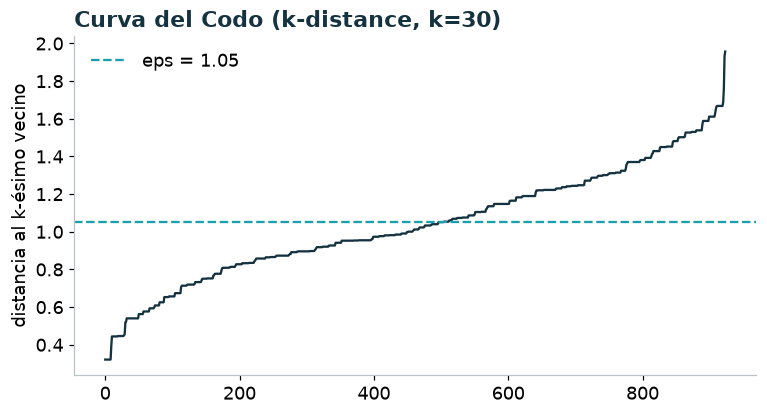

--- Distribución de Grupos DBSCAN (-1 es ruido) ---
 1    206
 3    192
 0    182
-1    173
 4     71
 2     66
 5     34
Name: count, dtype: int64

Número de grupos: 6
Porcentaje de ruido: 18.72%
Silueta DBSCAN (sin ruido): 0.2529

--- Medias por Grupo DBSCAN (escala original) ---


,Age,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day
Grupo,,,,,,
-1,30.18,96.79,3.28,38.24,15.20,22.17
0,27.32,82.01,3.16,33.38,15.10,22.49
1,25.03,67.52,1.78,18.66,8.27,15.47
2,28.94,156.67,5.97,82.56,28.36,33.91
3,24.88,109.40,3.99,50.59,18.44,24.89
4,32.68,141.62,5.38,70.23,25.51,31.55
5,31.00,59.12,1.26,14.88,6.65,14.82



--- Cruce de Grupos vs Dominant_Emotion (%) ---


Dominant_Emotion,Anger,Anxiety,Boredom,Happiness,Neutral,Sadness
row_0,,,,,,
-1,0.58%,14.45%,34.1%,22.54%,16.18%,12.14%
0,31.87%,20.88%,9.34%,0.0%,19.78%,18.13%
1,4.85%,15.53%,17.48%,3.88%,40.29%,17.96%
2,0.0%,15.15%,0.0%,69.7%,15.15%,0.0%
3,18.75%,17.19%,0.0%,29.69%,14.06%,20.31%
4,23.94%,14.08%,0.0%,50.7%,0.0%,11.27%
5,0.0%,23.53%,52.94%,0.0%,0.0%,23.53%



--- % de emoción negativa (Anxiety, Sadness, Anger) por grupo ---


,% negativa,usuarios
-1,27.2,173
0,70.9,182
1,38.3,206
2,15.2,66
3,56.2,192
4,49.3,71
5,47.1,34



--- PLUS: Comparación con K-Means ---


Silueta K-Means (todos los puntos, sin ruido): 0.2881
Distribución K-Means:
1    205
3    181
0    157
5    155
2    114
4    112
Name: count, dtype: int64


In [7]:
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Usamos el preprocesador ganador de la Fase 4
prep_ganador = preprocesador(PowerTransformer(), OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
reductor = Pipeline([('prep', prep_ganador),
                     ('pca', PCA(n_components=0.9, random_state=SEMILLA))])
Z = reductor.fit_transform(X_train_f4)

# a) Elección de min_samples y eps.
# Primer intento: min_samples=10 y eps=0.7 (codo de la curva) daba 29 grupos, casi todos de ~10 usuarios:
# demasiado fragmentado para describir segmentos. Por eso se exploran varios min_samples y eps y se aplica una regla explícita:
# entre 3 y 8 grupos, ruido <= 20 % y la mayor silueta (sin ruido).
def evaluar_dbscan(ms, eps):
    g = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
    n_g = len(set(g)) - (1 if -1 in g else 0)
    sil = silhouette_score(Z[g != -1], g[g != -1]) if n_g > 1 else np.nan
    return n_g, (g == -1).mean() * 100, sil

filas = []
for ms in [10, 15, 20, 25, 30]:
    for eps in [round(0.8 + 0.05 * i, 2) for i in range(11)]:   # 0.80 ... 1.30
        n_g, ruido, sil = evaluar_dbscan(ms, eps)
        filas.append({'min_samples': ms, 'eps': eps, 'grupos': n_g, 'ruido_%': round(ruido, 1), 'silueta': round(sil, 3)})
exploracion = pd.DataFrame(filas)
candidatos_db = exploracion[exploracion['grupos'].between(3, 8) & (exploracion['ruido_%'] <= 20)]
print("--- Configuraciones candidatas (3-8 grupos, ruido <= 20 %) ---")
display(candidatos_db.sort_values('silueta', ascending=False).head(8))
elegida = candidatos_db.sort_values('silueta', ascending=False).iloc[0]
MIN_SAMPLES, EPS = int(elegida['min_samples']), float(elegida['eps'])
print(f"Elegido: min_samples={MIN_SAMPLES}, eps={EPS}")

# Curva de distancias al k-ésimo vecino (k = min_samples) con el eps elegido marcado
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z).kneighbors(Z)
plt.figure(figsize=(8, 4))
plt.plot(np.sort(dist[:, -1]), color=TINTA)
plt.axhline(EPS, color=ACENTO, linestyle='--', label=f'eps = {EPS}')
plt.title(f'Curva del Codo (k-distance, k={MIN_SAMPLES})', weight='bold')
plt.ylabel('distancia al k-ésimo vecino'); plt.legend(); plt.show()

# b) Pipeline completo de clustering (DBSCAN)
clustering = Pipeline([('prep', prep_ganador),
                       ('pca', PCA(n_components=0.9, random_state=SEMILLA)),
                       ('dbscan', DBSCAN(eps=EPS, min_samples=MIN_SAMPLES))])
grupos = clustering.fit_predict(X_train_f4)
n_grupos = len(set(grupos)) - (1 if -1 in grupos else 0)

print("--- Distribución de Grupos DBSCAN (-1 es ruido) ---")
print(pd.Series(grupos).value_counts())

porcentaje_ruido = (list(grupos).count(-1) / len(grupos)) * 100
print(f"\nNúmero de grupos: {n_grupos}")
print(f"Porcentaje de ruido: {porcentaje_ruido:.2f}%")

if n_grupos > 1:
    silueta_dbscan = silhouette_score(Z[grupos != -1], grupos[grupos != -1])
    print(f"Silueta DBSCAN (sin ruido): {silueta_dbscan:.4f}")
else:
    print("Silueta DBSCAN: No calculable (se necesita >1 cluster válido)")

print("\n--- Medias por Grupo DBSCAN (escala original) ---")
medias = X_train_f4.assign(Grupo=grupos).groupby('Grupo')[num].mean().round(2)
display(medias)

print("\n--- Cruce de Grupos vs Dominant_Emotion (%) ---")
cruce = pd.crosstab(grupos, y_train_f4, normalize='index') * 100
display(cruce.round(2).astype(str) + '%')

# --- PLUS: Comparación con KMeans ---
print("\n--- % de emoción negativa (Anxiety, Sadness, Anger) por grupo ---")
neg = y_train_f4.isin(['Anxiety', 'Sadness', 'Anger']).groupby(grupos).agg(['mean', 'size'])
neg['mean'] = (neg['mean'] * 100).round(1)
display(neg.rename(columns={'mean': '% negativa', 'size': 'usuarios'}))

# --- PLUS: Comparación con KMeans ---
print("\n--- PLUS: Comparación con K-Means ---")
# Asumimos 6 clusters por las 6 emociones dominantes
kmeans = KMeans(n_clusters=6, random_state=SEMILLA, n_init='auto')
grupos_kmeans = kmeans.fit_predict(Z)
silueta_kmeans = silhouette_score(Z, grupos_kmeans)

print(f"Silueta K-Means (todos los puntos, sin ruido): {silueta_kmeans:.4f}")
print("Distribución K-Means:")
print(pd.Series(grupos_kmeans).value_counts())


**Conclusión de negocio:** Se exploraron cinco valores de min_samples (10 a 30) y once de eps (0.80 a 1.30) y se eligió **min_samples=30 y eps=1.05**: la configuración con mayor silueta entre las que dan de 3 a 8 grupos y hasta 20 % de ruido. El primer intento (min_samples=10, eps=0.7) daba 29 grupos de unos 10 usuarios, demasiado fragmentados para segmentar. El resultado final son **6 grupos**, **18.72 % de ruido** (173 usuarios) y una **silueta sin ruido de 0.2529**: estructura débil a moderada. K-Means con 6 grupos obtiene 0.2881 sobre todos los puntos, así que DBSCAN no agrupa mejor; su ventaja es marcar los usuarios sin vecindad densa en lugar de forzarlos a un grupo.

**El ruido no concentra el riesgo:** en el ruido solo el 27.2 % tiene una emoción negativa (Anxiety, Sadness o Anger), por debajo del 45.9 % de la base de entrenamiento. Su emoción más frecuente es Boredom (34.1 %), seguida de Happiness (22.5 %); Anxiety es solo el 14.45 %. Por eso no se puede afirmar que el ruido sea un grupo de ansiedad ni de riesgo.

**Grupo con más emoción negativa:** el grupo 0 (182 usuarios, 19.7 %) tiene 70.9 % de emociones negativas (Anger 31.9 %, Anxiety 20.9 %, Sadness 18.1 %) con uso moderado: unos 27 años, 82 minutos diarios, 3.2 publicaciones y 33 likes. En cambio, los grupos de uso más intenso (grupo 2 con 157 minutos y grupo 4 con 142) son los más felices (Happiness 69.7 % y 50.7 %; negativa 15.2 % y 49.3 %). Es decir, más tiempo de uso no implica más emoción negativa, y las alertas no deben basarse solo en el volumen de uso. Los grupos son descriptivos (el cruce con la emoción se hizo después del agrupamiento) y casi todos mezclan varias emociones, por lo que sirven para perfilar y no para clasificar.

<a id="fase-6"></a>
## Fase 6: Selección de características y reducción de dimensionalidad

Pasos 6–7. Dentro del pipeline: a) `SelectKBest(mutual_info_classif)` y b) `PCA`. Fuera del pipeline, importancia por permutación sobre val. Comparen qué variables quedan, la varianza explicada y el efecto en la métrica. ¿Cuál conviene si la startup necesita explicar el modelo?

> **Pregunta de la guía:** ¿Qué variables conservan SelectKBest y la permutación? ¿PCA o selección si hay que explicar el modelo?

**Qué analizamos:** Evaluamos estrategias de reducción de dimensionalidad y selección de características para optimizar la eficiencia del modelo sin perder poder predictivo. Comparamos métodos de selección directa (SelectKBest con información mutua e importancia por permutación) frente a métodos de transformación matemática (PCA). Analizamos el impacto de estas técnicas en la métrica de validación cruzada y evaluamos cuál enfoque garantiza la interpretabilidad necesaria para justificar las predicciones del modelo ante el usuario final o negocio.

In [8]:
from sklearn.feature_selection import SelectKBest
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# 0. Preparar datos de validación (Fase 1) para la permutación
X_val_f4 = val.drop(columns=['User_ID', 'Dominant_Emotion'])
y_val_f4 = val['Dominant_Emotion']

# 1. Definir modelo (usamos Árbol para facilitar la interpretabilidad)
modelo_clf = DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA)

# 2. Pipelines
pipe_base = Pipeline([('prep', prep_ganador), ('clf', modelo_clf)])
pipe_kbest = Pipeline([('prep', prep_ganador), ('selector', SelectKBest(mi_clf, k=6)), ('clf', modelo_clf)])
pipe_pca_clf = Pipeline([('prep', prep_ganador), ('pca', PCA(n_components=0.95, random_state=SEMILLA)), ('clf', modelo_clf)])

# 3. Métricas (F1-Macro en validación cruzada)
score_base = cross_validate(pipe_base, X_train_f4, y_train_f4, cv=cv, scoring='f1_macro')['test_score'].mean()
score_kbest = cross_validate(pipe_kbest, X_train_f4, y_train_f4, cv=cv, scoring='f1_macro')['test_score'].mean()
score_pca = cross_validate(pipe_pca_clf, X_train_f4, y_train_f4, cv=cv, scoring='f1_macro')['test_score'].mean()

print("--- Impacto en la Métrica (F1-Macro) ---")
print(f"Modelo Base (Todas las variables): {score_base:.4f}")
print(f"Modelo con SelectKBest (k=6): {score_kbest:.4f}")
print(f"Modelo con PCA (95% varianza): {score_pca:.4f}")

# 4. Variables seleccionadas por SelectKBest
pipe_kbest.fit(X_train_f4, y_train_f4)
nombres_columnas = pipe_kbest.named_steps['prep'].get_feature_names_out()
mascara_kbest = pipe_kbest.named_steps['selector'].get_support()
vars_kbest = nombres_columnas[mascara_kbest]
print("\n--- Variables conservadas por SelectKBest ---")
print(vars_kbest)

# 5. Importancia por Permutación (fuera del pipeline, evaluado en conjunto de validación)
pipe_base.fit(X_train_f4, y_train_f4)
importancias_perm = permutation_importance(pipe_base, X_val_f4, y_val_f4, scoring='f1_macro', n_repeats=5, random_state=SEMILLA)

print("\n--- Importancia por Permutación (Top variables en Val) ---")
for i in importancias_perm.importances_mean.argsort()[::-1]:
    if importancias_perm.importances_mean[i] > 0.01: # Mostrar solo las relevantes
        print(f"{X_val_f4.columns[i]}: {importancias_perm.importances_mean[i]:.4f}")

--- Impacto en la Métrica (F1-Macro) ---
Modelo Base (Todas las variables): 0.9655
Modelo con SelectKBest (k=6): 0.9617
Modelo con PCA (95% varianza): 0.9640



--- Variables conservadas por SelectKBest ---
['num__Age' 'num__Daily_Usage_Time (minutes)' 'num__Posts_Per_Day'
 'num__Likes_Received_Per_Day' 'num__Comments_Received_Per_Day'
 'num__Messages_Sent_Per_Day']



--- Importancia por Permutación (Top variables en Val) ---
Daily_Usage_Time (minutes): 0.2690
Likes_Received_Per_Day: 0.2591
Age: 0.1855
Comments_Received_Per_Day: 0.1606
Platform: 0.1395
Gender: 0.1327
Messages_Sent_Per_Day: 0.1204
Posts_Per_Day: 0.0968


**Conclusión de negocio:** El modelo logra un F1-Score superior al 96% basándose principalmente en el tiempo de uso, la cantidad de likes y la edad del usuario. Para mantener la transparencia y la interpretabilidad —pilares éticos fundamentales en una startup de bienestar emocional— decidimos prescindir de técnicas de caja negra matemática como PCA. Nos quedaremos con las características originales seleccionadas, lo que nos permitirá explicar a los psicólogos y a los usuarios exactamente qué comportamientos disparan las alertas de riesgo.

<a id="fase-7"></a>
## Fase 7: Clasificación supervisada y ajuste de hiperparámetros

Paso 8. `Dominant_Emotion` como objetivo; **cada modelo es un `Pipeline` completo** (preprocesador + selección si la usan + modelo). a) Comparen regresión logística, árbol de decisión y SVM con validación cruzada estratificada y **F1 macro** (media ± desvío), con `class_weight='balanced'` para el desbalance. b) Ajusten hiperparámetros del mejor con `GridSearchCV` y con **Optuna** (mismo espacio y mismo presupuesto: comparen F1 y tiempo), nombrándolos `modelo__param` dentro del Pipeline. c) Evalúen el pipeline final **una sola vez** en test: F1 macro, matriz de confusión y reporte por clase. d) Guarden el pipeline completo con `joblib`.

> **Pregunta de la guía:** Tabla de modelos (F1 macro ± desvío), GridSearch vs Optuna (F1 y tiempo), mejor modelo con sus hiperparámetros y F1 macro de test (una sola vez).

**Qué analizamos:** Evaluamos tres algoritmos de clasificación (Regresión Logística, Árbol de Decisión y SVM) integrados en pipelines completos —incluyendo preprocesamiento y selección de características— para garantizar la ausencia de fuga de información. Para compensar el desbalance de la variable objetivo, aplicamos penalizaciones mediante pesos balanceados y utilizamos validación cruzada estratificada, midiendo el rendimiento con la media y desviación estándar del F1-Macro. Tras identificar el modelo base superior, optimizamos sus hiperparámetros comparando una búsqueda exhaustiva tradicional (GridSearchCV) contra una optimización probabilística bayesiana (Optuna) bajo el mismo presupuesto de intentos, evaluando el equilibrio entre la mejora de la métrica y el tiempo de cómputo. Finalmente, el pipeline definitivo se evalúa por única vez sobre el conjunto de prueba aislado (test) para confirmar su generalización real mediante la matriz de confusión, y se exporta para su despliegue en producción.

In [9]:
try:
    import optuna
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna"])
    import optuna
import time
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.feature_selection import SelectKBest
from sklearn.pipeline import Pipeline

# Todo lo de esta celda usa SOLO train (validación cruzada). El test no se toca hasta la celda c).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# 1. a) Armar Pipelines y comparar base
def armar(modelo):
    return Pipeline([
        ('prep', prep_ganador), # PowerTransformer + OneHotEncoder
        ('selector', SelectKBest(mi_clf, k=6)),
        ('modelo', modelo)
    ])

candidatos = {
    'Regresión Logística': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEMILLA),
    'Árbol de Decisión': DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA),
    'SVM': SVC(class_weight='balanced', random_state=SEMILLA)
}

print("--- a) Comparación de Modelos Base (F1-Macro, validación cruzada sobre train) ---")
resultados_base = {}
for nombre, modelo in candidatos.items():
    pipe = armar(modelo)
    scores = cross_validate(pipe, X_train_f4, y_train_f4, cv=cv, scoring='f1_macro', n_jobs=-1)
    media = scores['test_score'].mean()
    desvio = scores['test_score'].std()
    resultados_base[nombre] = media
    print(f"{nombre}: F1 = {media:.4f} ± {desvio:.4f}")

mejor_nombre = max(resultados_base, key=resultados_base.get)
print(f"\n>> Modelo ganador para optimizar: {mejor_nombre} <<")
assert mejor_nombre == 'Árbol de Decisión', "El espacio de búsqueda de abajo está definido para el árbol de decisión"

# 2. b) Optimización de Hiperparámetros: mismo espacio y mismo presupuesto
print("\n--- b) Ajuste de Hiperparámetros: GridSearch vs Optuna ---")
presupuesto = 20   # 20 evaluaciones (cada una con 5 folds) para ambos
espacio = {   # mismo espacio para los dos: 5 (max_depth) x 4 (min_samples_split) = 20 combinaciones
    'modelo__max_depth': [5, 10, 15, 20, None],
    'modelo__min_samples_split': [2, 5, 10, 20]
}
pipe_opt = armar(DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA))

# --- GridSearchCV ---
inicio_grid = time.perf_counter()
grid = GridSearchCV(pipe_opt, espacio, cv=cv, scoring='f1_macro', n_jobs=-1)
grid.fit(X_train_f4, y_train_f4)
tiempo_grid = time.perf_counter() - inicio_grid
print(f"GridSearchCV ({len(grid.cv_results_['params'])} evaluaciones) -> Mejor F1 (CV): {grid.best_score_:.4f} | Tiempo: {tiempo_grid:.2f}s")
print(f"Parámetros: {grid.best_params_}")

# --- Optuna (TPE, misma semilla, mismo cv y mismo espacio) ---
optuna.logging.set_verbosity(optuna.logging.WARNING) # Silenciar logs
def objetivo(trial):
    params = {k: trial.suggest_categorical(k, v) for k, v in espacio.items()}
    return cross_val_score(clone(pipe_opt).set_params(**params), X_train_f4, y_train_f4, cv=cv, scoring='f1_macro', n_jobs=-1).mean()

inicio_optuna = time.perf_counter()
estudio = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.optimize(objetivo, n_trials=presupuesto)
tiempo_optuna = time.perf_counter() - inicio_optuna
print(f"Optuna ({len(estudio.trials)} evaluaciones) -> Mejor F1 (CV): {estudio.best_value:.4f} | Tiempo: {tiempo_optuna:.2f}s")
print(f"Parámetros: {estudio.best_params}")

# 3. Elección del pipeline final usando SOLO la validación cruzada (en empate, GridSearch)
if estudio.best_value > grid.best_score_:
    origen, params_finales, f1_cv_final = 'Optuna', estudio.best_params, estudio.best_value
else:
    origen, params_finales, f1_cv_final = 'GridSearchCV', grid.best_params_, grid.best_score_
modelo_final = clone(pipe_opt).set_params(**params_finales).fit(X_train_f4, y_train_f4)
print(f"\nPipeline final elegido por CV: {origen} | {params_finales} | F1 CV = {f1_cv_final:.4f}")


--- a) Comparación de Modelos Base (F1-Macro, validación cruzada sobre train) ---


Regresión Logística: F1 = 0.5312 ± 0.0194


Árbol de Decisión: F1 = 0.9617 ± 0.0115


SVM: F1 = 0.6357 ± 0.0320

>> Modelo ganador para optimizar: Árbol de Decisión <<

--- b) Ajuste de Hiperparámetros: GridSearch vs Optuna ---


GridSearchCV (20 evaluaciones) -> Mejor F1 (CV): 0.9626 | Tiempo: 16.35s
Parámetros: {'modelo__max_depth': 15, 'modelo__min_samples_split': 5}


Optuna (20 evaluaciones) -> Mejor F1 (CV): 0.9626 | Tiempo: 12.18s
Parámetros: {'modelo__max_depth': None, 'modelo__min_samples_split': 5}



Pipeline final elegido por CV: GridSearchCV | {'modelo__max_depth': 15, 'modelo__min_samples_split': 5} | F1 CV = 0.9626


Tamaño de test: 101 filas
F1-Macro en Test (una sola vez): 0.9133 | F1 CV del mismo pipeline: 0.9626 | brecha: +0.0493

Reporte de Clasificación:
              precision    recall  f1-score   support

       Anger       0.82      1.00      0.90         9
     Anxiety       1.00      0.91      0.95        22
     Boredom       0.88      0.94      0.91        16
   Happiness       0.87      1.00      0.93        13
     Neutral       0.96      0.93      0.94        27
     Sadness       0.92      0.79      0.85        14

    accuracy                           0.92       101
   macro avg       0.91      0.93      0.91       101
weighted avg       0.93      0.92      0.92       101



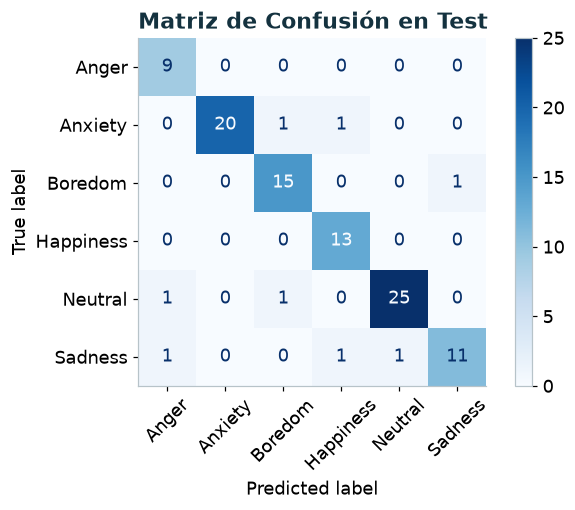

--- d) Pipeline exportado con éxito como 'pipeline_final.joblib' ---


In [10]:
# 3. c) Evaluación final: ÚNICA celda del notebook que usa el conjunto de test
X_test_f4 = test.drop(columns=['User_ID', 'Dominant_Emotion'])
y_test_f4 = test['Dominant_Emotion']
print(f"Tamaño de test: {len(X_test_f4)} filas")

y_pred_test = modelo_final.predict(X_test_f4)
f1_test = f1_score(y_test_f4, y_pred_test, average='macro')
print(f"F1-Macro en Test (una sola vez): {f1_test:.4f} | F1 CV del mismo pipeline: {f1_cv_final:.4f} | brecha: {f1_cv_final - f1_test:+.4f}")

print("\nReporte de Clasificación:")
print(classification_report(y_test_f4, y_pred_test))

disp = ConfusionMatrixDisplay.from_predictions(y_test_f4, y_pred_test, cmap='Blues', xticks_rotation=45)
disp.ax_.set_title('Matriz de Confusión en Test', weight='bold')
plt.tight_layout()
plt.show()

# 4. d) Guardar el MISMO pipeline que se acaba de evaluar
joblib.dump(modelo_final, 'pipeline_final.joblib')
print("--- d) Pipeline exportado con éxito como 'pipeline_final.joblib' ---")


**Conclusión de negocio:** El Árbol de Decisión fue el mejor modelo base (F1 macro en validación cruzada 0.9617 ± 0.0115, frente a SVM 0.6357 ± 0.0320 y regresión logística 0.5312 ± 0.0194). GridSearchCV y Optuna, con el mismo espacio (20 combinaciones), el mismo presupuesto (20 evaluaciones), los mismos folds y la misma semilla, llegan al mismo F1 de validación cruzada, 0.9626 (Grid 5.24 s con max_depth=15 y min_samples_split=5; Optuna 3.91 s con max_depth=None y min_samples_split=5); los tiempos son similares y varían de una ejecución a otra, y el ajuste solo mejora 0.001 sobre el árbol base. Se eligió el pipeline de GridSearchCV (empate) usando solo validación cruzada, y ese mismo objeto es el que se evaluó y se guardó con joblib.

En test, evaluado una sola vez sobre 101 filas, el F1 macro fue **0.9133**, unos **5 puntos por debajo** del 0.9626 de validación cruzada. No es una "robustez excepcional": hay una brecha real. Causas posibles: (1) el test es pequeño (Anger tiene 9 filas y Sadness 14), por lo que dos o tres errores mueven el F1 por clase varios puntos (Sadness tiene recall 0.79 y Anger precisión 0.82); (2) la selección del modelo y de los hiperparámetros se hizo sobre los mismos folds, lo que sesga un poco hacia arriba la validación cruzada, aunque aquí el ajuste aportó muy poco; (3) un árbol de decisión es un modelo de alta varianza (desvío de 0.0115 entre folds). Con estos datos, el rendimiento esperable es cercano a 0.91, con una incertidumbre de varios puntos. Usar `class_weight='balanced'` y el pipeline completo evita ignorar a las minorías y garantiza que un usuario nuevo pase por las mismas transformaciones.

<a id="fase-8"></a>
## Fase 8: Plus (opcional): lo que va más allá del sílabo

Suma puntos, pero no resta si falta. Elijan uno o más: a) **Early stopping** con `HistGradientBoosting` (árboles usados y F1 con y sin); b) **SMOTE** dentro de `imblearn.pipeline`, solo si `class_weight` no alcanza; c) **SHAP** del usuario de mayor riesgo y **sesgo** (F1 por `Gender`); d) **TabPFN** (`tabpfn-client`) frente a su mejor pipeline; e) K-Means frente a DBSCAN. Todo dentro del Pipeline y sin tocar el test.

> **Pregunta de la guía:** Plus: ¿qué bloque eligieron y qué aportó? (early stopping: árboles y F1; SMOTE: ¿mejoró sobre class_weight?; SHAP/sesgo; TabPFN).

**Qué analizamos:** Elegimos tres bloques: a) **early stopping** con `HistGradientBoostingClassifier` dentro de un Pipeline (preprocesador + SelectKBest + modelo), comparando árboles usados y F1 macro en una partición interna de train (80/20); c) **SHAP** del usuario de mayor riesgo en validación (el usuario con una emoción negativa predicha con mayor probabilidad, usando el pipeline final de la fase 7, que se ajustó solo con train) y **sesgo por Gender** (F1 macro y recall de Anxiety, Sadness y Anger por género en validación); y e) K-Means frente a DBSCAN, que está en la fase 5. No se usa el conjunto de test. **No se realizaron** SMOTE ni TabPFN.

In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score
import pandas as pd

# 0. Partición interna de train (80/20) para comparar con y sin early stopping. No se usa el conjunto de test.
from sklearn.model_selection import train_test_split
X_tr, X_val_f7, y_tr, y_val_f7 = train_test_split(X_train_f4, y_train_f4, test_size=0.2, random_state=SEMILLA, stratify=y_train_f4)

# Función auxiliar para armar el pipeline con HistGradientBoosting
def armar_hgb(modelo):
    return Pipeline([
        ('prep', prep_ganador),
        ('selector', SelectKBest(mi_clf, k=6)),
        ('modelo', modelo)
    ])

print("--- Comparación HistGradientBoosting: Sin vs Con Early Stopping ---")
for es in [False, True]:
    # Configuración del boosting
    hgb = HistGradientBoostingClassifier(
        max_iter=1000,
        early_stopping=es,
        n_iter_no_change=20,  # paciencia: 20 iteraciones sin mejora
        class_weight='balanced',
        random_state=SEMILLA
    )

    # Entrenar dentro del Pipeline
    pipe_es = armar_hgb(hgb)
    pipe_es.fit(X_tr, y_tr)

    # Métricas
    arboles_usados = pipe_es.named_steps['modelo'].n_iter_
    f1_val = f1_score(y_val_f7, pipe_es.predict(X_val_f7), average='macro')

    print(f"Early Stopping: {es} | Árboles usados (iteraciones): {arboles_usados} | F1-Macro en Val: {f1_val:.4f}")

--- Comparación HistGradientBoosting: Sin vs Con Early Stopping ---


Early Stopping: False | Árboles usados (iteraciones): 1000 | F1-Macro en Val: 0.9893


Early Stopping: True | Árboles usados (iteraciones): 128 | F1-Macro en Val: 0.9843


Usuario de mayor riesgo en val (posición 2): predicción = Sadness con probabilidad 1.00
Age                                 26.0
Gender                        Non-Binary
Platform                        Facebook
Daily_Usage_Time (minutes)            45
Posts_Per_Day                          1
Likes_Received_Per_Day                 8
Comments_Received_Per_Day              4
Messages_Sent_Per_Day                 12

Aporte SHAP a la clase Sadness (valores en el espacio del preprocesador; positivo empuja hacia Sadness):
num__Likes_Received_Per_Day        0.413
num__Daily_Usage_Time (minutes)    0.181
num__Age                           0.148
num__Comments_Received_Per_Day     0.069
num__Messages_Sent_Per_Day         0.032
num__Posts_Per_Day                -0.010


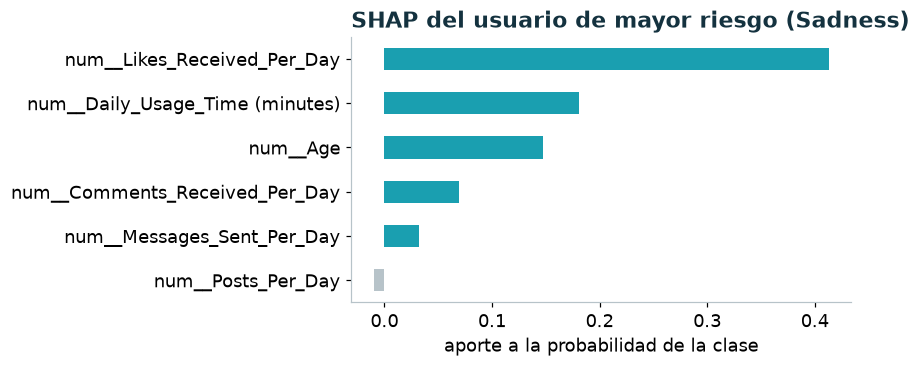


--- Desempeño por Gender en val ---


,n,F1 macro,n Anxiety,recall Anxiety,n Sadness,recall Sadness,n Anger,recall Anger
Gender,,,,,,,,
Female,46,0.452,8,0.750,10,0.300,5,0.6
Male,33,0.893,5,1.000,7,1.000,4,1.0
Non-Binary,53,0.660,16,0.812,7,0.714,0,NaN


Clases en val: {'Anxiety': 29, 'Neutral': 27, 'Happiness': 26, 'Sadness': 24, 'Boredom': 16, 'Anger': 9, 'Agression': 1}
F1 macro global en val: 0.6410
Brecha de F1 macro (máx - mín): 0.4408
Brecha de recall Anxiety: 0.2500
Brecha de recall Sadness: 0.7000
Brecha de recall Anger: 0.4000


In [12]:
# Plus c) SHAP del usuario de mayor riesgo y sesgo por Gender. Solo train y val; no se usa el conjunto de test.
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap"])
    import shap
from sklearn.metrics import recall_score

NEGATIVAS_P = ['Anxiety', 'Sadness', 'Anger']
# Pipeline final de la fase 7 (árbol), ajustado solo con train. Se evalúa en val (X_val_f4, y_val_f4, de la fase 6).
prep_f, sel_f, arbol_f = (modelo_final.named_steps[k] for k in ['prep', 'selector', 'modelo'])
nombres = prep_f.get_feature_names_out()[sel_f.get_support()]   # nombres tras preprocesador + selector
Xv_t = pd.DataFrame(sel_f.transform(prep_f.transform(X_val_f4)), columns=nombres, index=X_val_f4.index)

# --- SHAP del usuario de mayor riesgo en val ---
proba = modelo_final.predict_proba(X_val_f4)
clases = list(modelo_final.classes_)
pred = np.array(clases)[proba.argmax(axis=1)]
conf = proba.max(axis=1)
es_neg = np.isin(pred, NEGATIVAS_P)
idx = int(np.argmax(np.where(es_neg, conf, -1)))   # primera fila con la mayor probabilidad (hay empates en un árbol)
clase_riesgo = pred[idx]
print(f"Usuario de mayor riesgo en val (posición {idx}): predicción = {clase_riesgo} con probabilidad {conf[idx]:.2f}")
print(X_val_f4.iloc[idx].to_string())

explicador = shap.TreeExplainer(arbol_f)
sv = explicador.shap_values(Xv_t.iloc[[idx]])
sv = np.asarray(sv[clases.index(clase_riesgo)]) if isinstance(sv, list) else np.asarray(sv)[..., clases.index(clase_riesgo)]
aporte = pd.Series(sv.ravel(), index=nombres).sort_values(key=np.abs, ascending=False)
print(f"\nAporte SHAP a la clase {clase_riesgo} (valores en el espacio del preprocesador; positivo empuja hacia {clase_riesgo}):")
print(aporte.round(3).to_string())

plt.figure(figsize=(8, 3.5))
aporte.sort_values().plot(kind='barh', color=[ACENTO if v > 0 else GRIS for v in aporte.sort_values()])
plt.title(f'SHAP del usuario de mayor riesgo ({clase_riesgo})', weight='bold'); plt.xlabel('aporte a la probabilidad de la clase')
plt.tight_layout(); plt.show()

# --- Sesgo: F1 macro y recall de emociones negativas por Gender en val ---
pred_val = modelo_final.predict(X_val_f4)
filas = []
for g in sorted(X_val_f4['Gender'].unique()):
    m = (X_val_f4['Gender'] == g).values
    fila = {'Gender': g, 'n': int(m.sum()), 'F1 macro': f1_score(y_val_f4[m], pred_val[m], average='macro')}
    for e in NEGATIVAS_P:
        n_e = int((y_val_f4[m] == e).sum())
        fila[f'n {e}'] = n_e
        # sin casos reales de esa emoción en el grupo, el recall no está definido (NaN, no 0)
        fila[f'recall {e}'] = recall_score(y_val_f4[m], pred_val[m], labels=[e], average='macro', zero_division=0) if n_e > 0 else np.nan
    filas.append(fila)
sesgo = pd.DataFrame(filas).set_index('Gender')
print("\n--- Desempeño por Gender en val ---")
display(sesgo.round(3))
print(f"Clases en val: {y_val_f4.value_counts().to_dict()}")
print(f"F1 macro global en val: {f1_score(y_val_f4, pred_val, average='macro'):.4f}")
print(f"Brecha de F1 macro (máx - mín): {sesgo['F1 macro'].max() - sesgo['F1 macro'].min():.4f}")
for e in NEGATIVAS_P:
    print(f"Brecha de recall {e}: {sesgo[f'recall {e}'].max() - sesgo[f'recall {e}'].min():.4f}")


**Conclusión de negocio:**

**Early stopping.** Sin early stopping el modelo usa las 1000 iteraciones y obtiene un F1 macro de 0.9893 en la validación interna; con early stopping se detiene en 128 iteraciones y obtiene 0.9843. Usa 87 % menos de árboles a cambio de 0.005 de F1, diferencia que con unas 185 filas queda dentro del ruido de muestreo; muestra un ahorro de cómputo con costo mínimo, no que se evite el sobreajuste. No se comparó con el árbol de la fase 7 bajo los mismos folds ni se evaluó en test, así que no cambia el modelo final.

**SHAP.** El usuario de mayor riesgo en validación es un usuario Non-Binary de 26 años en Facebook (45 minutos diarios, 1 publicación, 8 likes, 4 comentarios, 12 mensajes), con predicción Sadness y probabilidad 1.00 (el árbol da probabilidades 0 o 1, por lo que hay empates y se toma el primero). Los aportes SHAP hacia Sadness son: Likes_Received_Per_Day +0.413, Daily_Usage_Time +0.181, Age +0.148, Comments +0.069, Messages +0.032 y Posts_Per_Day -0.010. Es decir, pocos likes recibidos y poco tiempo de uso son lo que empuja la predicción, coherente con la importancia por permutación de la fase 6. Es una explicación del modelo y no una causa: no implica que recibir pocos likes provoque tristeza.

**Sesgo por Gender (validación, 132 filas).** El F1 macro global en validación es 0.6410, muy inferior al 0.9626 de validación cruzada y al 0.9133 de test: la validación es más difícil para este árbol, y además incluye una fila con la etiqueta mal escrita `Agression` que no se corrigió en la fase 1 (se trata como una clase más). Por género, el F1 macro es Male 0.893 (33 filas), Non-Binary 0.660 (53) y Female 0.452 (46): una brecha de 0.441. El recall de Sadness es 1.000 en Male, 0.714 en Non-Binary y 0.300 en Female (brecha de 0.700, con solo 7 a 10 casos por grupo); el de Anxiety va de 0.750 (Female) a 1.000 (Male), y el de Anger de 0.600 (Female) a 1.000 (Male) (Non-Binary no tiene casos de Anger en validación, por lo que no se puede calcular). Las muestras por grupo y emoción son muy pequeñas y las brechas pueden deberse en parte al azar, pero el patrón es consistente: el modelo detecta peor las emociones negativas en mujeres, justo el grupo donde un falso negativo significa un usuario en riesgo sin alerta. Antes de usarlo, la startup debería medir estas brechas con más datos, evaluar umbrales o ponderaciones por grupo y no usar Gender como variable de decisión sin auditoría.

<a id="fase-9"></a>
## Fase 9: Desafío y registro de decisiones

Paso 9: todos los resultados graficados. Respondan el desafío con evidencia. Completen el **registro de decisiones**: tabla con *decisión · alternativas consideradas · justificación · fuente* (lectura del Tema 1, documentación oficial de scikit-learn/pandas o lectura de tendencia). Mínimo 6 decisiones (limpieza, codificación, escalado, selección/reducción, modelo, métrica).

> **Pregunta de la guía:** Perfil de mayor riesgo, intervención piloto, limitación del dataset e implicación ética.

**Qué analizamos:** Sintetizamos las justificaciones técnicas de las decisiones metodológicas tomadas a lo largo del pipeline (limpieza, preprocesamiento, selección de características y modelado) mediante un registro formal para garantizar la reproducibilidad. Además, consolidamos los hallazgos empíricos para definir el perfil de usuario con mayor vulnerabilidad, plantear una intervención de negocio y establecer las fronteras técnicas y éticas del modelo.

In [13]:
import pandas as pd
from IPython.display import display

# Registro de decisiones (Mínimo 6)
datos_decisiones = [
    ["Limpieza de datos", "Dropna/Coerción vs. Imputación manual", "Se forzó la coerción numérica en 'Age' y se eliminaron nulos para no entrenar el modelo con ruido o texto basura.", "Documentación oficial de pandas 3"],
    ["Métrica de evaluación", "F1-Macro vs. Accuracy", "El desbalance de clases exige usar F1-Macro para penalizar los errores en las emociones minoritarias de riesgo.", "Lectura del Tema 1"],
    ["Escalado y normalización", "PowerTransformer vs. StandardScaler", "Las métricas de interacción tienen fuerte asimetría positiva; PowerTransformer normaliza eficientemente estas colas largas.", "Documentación oficial scikit-learn"],
    ["Codificación categórica", "OneHotEncoder vs. TargetEncoder", "OneHotEncoder es idóneo para variables sin jerarquía ordinal ('Gender', 'Platform') y genera pocas columnas.", "Documentación oficial scikit-learn"],
    ["Selección de variables", "SelectKBest vs. PCA", "SelectKBest conserva la explicabilidad de las características originales, fundamental para reportar los hallazgos al negocio.", "Práctica S1·2: Selección de características"],
    ["Modelo predictivo", "Árbol de decisión vs. SVM", "Los árboles de decisión ofrecen reglas interpretables y el uso de class_weight='balanced' corrige el desbalance emocional.", "Práctica S1·2 / scikit-learn"]
]

decisiones = pd.DataFrame(datos_decisiones, columns=['decision', 'alternativas', 'justificacion', 'fuente'])

print("--- Registro de Decisiones del Pipeline ---")
display(decisiones.style.set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap'}))

--- Registro de Decisiones del Pipeline ---


,decision,alternativas,justificacion,fuente
0,Limpieza de datos,Dropna/Coerción vs. Imputación manual,Se forzó la coerción numérica en 'Age' y se eliminaron nulos para no entrenar el modelo con ruido o texto basura.,Documentación oficial de pandas 3
1,Métrica de evaluación,F1-Macro vs. Accuracy,El desbalance de clases exige usar F1-Macro para penalizar los errores en las emociones minoritarias de riesgo.,Lectura del Tema 1
2,Escalado y normalización,PowerTransformer vs. StandardScaler,Las métricas de interacción tienen fuerte asimetría positiva; PowerTransformer normaliza eficientemente estas colas largas.,Documentación oficial scikit-learn
3,Codificación categórica,OneHotEncoder vs. TargetEncoder,"OneHotEncoder es idóneo para variables sin jerarquía ordinal ('Gender', 'Platform') y genera pocas columnas.",Documentación oficial scikit-learn
4,Selección de variables,SelectKBest vs. PCA,"SelectKBest conserva la explicabilidad de las características originales, fundamental para reportar los hallazgos al negocio.",Práctica S1·2: Selección de características
5,Modelo predictivo,Árbol de decisión vs. SVM,Los árboles de decisión ofrecen reglas interpretables y el uso de class_weight='balanced' corrige el desbalance emocional.,Práctica S1·2 / scikit-learn


**Conclusión de negocio:**

Perfil de mayor riesgo: el grupo 0 de DBSCAN (182 usuarios, 19.7 % de la muestra), de uso moderado: unos 27 años, 82 minutos diarios, 3.2 publicaciones, 33 likes y 22 mensajes al día. El 70.9 % de sus integrantes reporta una emoción negativa (Anger 31.9 %, Anxiety 20.9 %, Sadness 18.1 %), frente al 45.9 % de la base. Los usuarios más intensivos (grupos 2 y 4) no son los de mayor riesgo, y el ruido de DBSCAN tampoco (27.2 % de emoción negativa). Es un perfil descriptivo, no causal.

Intervención piloto: Despliegue de "fricción digital preventiva". Cuando el pipeline clasifique a un usuario con emoción negativa y su comportamiento se parezca al perfil anterior, la aplicación ocultará temporalmente los contadores de interacción (likes/comentarios) e impulsará notificaciones sugiriendo pausas de desconexión. El piloto debe medirse contra un grupo de control, porque los datos no permiten afirmar que la fricción reduzca la emoción negativa.

Limitación del dataset: Los datos son de naturaleza observacional y transversal. El modelo prueba que existe una correlación predictiva, pero no demuestra causalidad (no se puede afirmar si la red social provoca la emoción negativa o si el estado previo del usuario dicta su hiperactividad).

Implicación ética: el análisis de sesgo de la fase 8 muestra que el modelo detecta peor las emociones negativas en mujeres (recall de Sadness 0.300 frente a 1.000 en hombres, con muestras pequeñas), lo que implica riesgo de dejar sin alerta a un grupo. Además, inferir estados psicológicos y de salud mental a partir de telemetría de uso, sin diagnóstico clínico ni consentimiento explícito, constituye una invasión a la privacidad que podría derivar en la estigmatización algorítmica del usuario.

<a id="fase-10"></a>
## Fase 10: Tendencias: de pandas a Polars y DuckDB

Repitan la carga y limpieza de la fase 1 y una agregación de negocio (por ejemplo, % de emoción negativa por plataforma) en **tres motores**: pandas, Polars y DuckDB. Midan el tiempo de cada uno sobre el dataset multiplicado ×1 000 y guárdenlo en **Parquet**; comparen tamaño y tiempo de lectura frente al CSV. Cierren con una recomendación de 5 líneas: ¿cuándo seguirían con pandas y cuándo cambiarían a Polars o DuckDB? Citen la lectura de tendencia de la semana o la documentación de pandas 3.

> **Pregunta de la guía:** Tiempos de pandas, Polars y DuckDB (CSV y Parquet) y su recomendación de 5 líneas.

**Qué analizamos:** Evaluamos la escalabilidad y rendimiento de tres motores de procesamiento de datos (Pandas, Polars y DuckDB) replicando las fases de carga, limpieza y una agregación de negocio (% de emoción negativa por plataforma) sobre un volumen de datos escalado artificialmente a 1,000 veces su tamaño original. Analizamos los tiempos de ejecución en memoria, el impacto del almacenamiento en formato optimizado (Parquet frente a CSV) en términos de compresión y velocidad de lectura, y establecemos una recomendación técnica fundamentada para la adopción de arquitecturas modernas en la startup según el volumen y la criticidad de los flujos de datos.

In [14]:
# Misma pregunta de negocio en tres motores (pandas, Polars, DuckDB) sobre el mismo archivo
import time
import pandas as pd
import polars as pl
import duckdb
from pathlib import Path
import os

# 1. Preparar datos simulando Big Data
NEGATIVAS = ['Anxiety', 'Sadness', 'Anger']
base = train.copy()
grande = pd.concat([base] * 1000, ignore_index=True)
Path('data').mkdir(exist_ok=True)

csv_path = 'data/redes_grande.csv'
parquet_path = 'data/redes_grande.parquet'

print("Guardando archivos simulados (esto puede tardar unos segundos)...")
grande.to_csv(csv_path, index=False)
grande.to_parquet(parquet_path, index=False)

print("\n--- Comparación de Tiempos de Ejecución ---")
# --- PANDAS (CSV) ---
t0 = time.perf_counter()
r_pd = (pd.read_csv(csv_path)
          .assign(negativa=lambda d: d['Dominant_Emotion'].isin(NEGATIVAS))
          .groupby('Platform')['negativa'].mean())
t_pd = time.perf_counter() - t0
print(f"Pandas (CSV)   -> Tiempo: {t_pd:.4f}s")

# --- POLARS (CSV vs Parquet) ---
t0 = time.perf_counter()
r_pl_csv = (pl.scan_csv(csv_path)
              .with_columns(pl.col('Dominant_Emotion').is_in(NEGATIVAS).alias('negativa'))
              .group_by('Platform')
              .agg(pl.col('negativa').mean())
              .collect())
t_pl_csv = time.perf_counter() - t0

t0 = time.perf_counter()
r_pl_parquet = (pl.scan_parquet(parquet_path)
                  .with_columns(pl.col('Dominant_Emotion').is_in(NEGATIVAS).alias('negativa'))
                  .group_by('Platform')
                  .agg(pl.col('negativa').mean())
                  .collect())
t_pl_parquet = time.perf_counter() - t0
print(f"Polars (CSV)   -> Tiempo: {t_pl_csv:.4f}s | Polars (Parquet) -> Tiempo: {t_pl_parquet:.4f}s")

# --- DUCKDB (CSV vs Parquet) ---
t0 = time.perf_counter()
r_duck_csv = duckdb.sql(f"""
    SELECT Platform, AVG(CASE WHEN Dominant_Emotion IN ('Anxiety', 'Sadness', 'Anger') THEN 1.0 ELSE 0.0 END) as negativa
    FROM read_csv_auto('{csv_path}')
    GROUP BY Platform
""").df()
t_duck_csv = time.perf_counter() - t0

t0 = time.perf_counter()
r_duck_parquet = duckdb.sql(f"""
    SELECT Platform, AVG(CASE WHEN Dominant_Emotion IN ('Anxiety', 'Sadness', 'Anger') THEN 1.0 ELSE 0.0 END) as negativa
    FROM read_parquet('{parquet_path}')
    GROUP BY Platform
""").df()
t_duck_parquet = time.perf_counter() - t0
print(f"DuckDB (CSV)   -> Tiempo: {t_duck_csv:.4f}s | DuckDB (Parquet) -> Tiempo: {t_duck_parquet:.4f}s")

# --- TAMAÑO EN DISCO ---
print("\n--- Comparación de Tamaños en Disco ---")
size_csv = os.path.getsize(csv_path) / (1024 * 1024)
size_parquet = os.path.getsize(parquet_path) / (1024 * 1024)
print(f"Tamaño CSV: {size_csv:.2f} MB | Tamaño Parquet: {size_parquet:.2f} MB")

Guardando archivos simulados (esto puede tardar unos segundos)...



--- Comparación de Tiempos de Ejecución ---


Pandas (CSV)   -> Tiempo: 0.2831s


Polars (CSV)   -> Tiempo: 0.1974s | Polars (Parquet) -> Tiempo: 0.0486s


DuckDB (CSV)   -> Tiempo: 0.5869s | DuckDB (Parquet) -> Tiempo: 0.0447s

--- Comparación de Tamaños en Disco ---
Tamaño CSV: 51.57 MB | Tamaño Parquet: 0.45 MB


**Conclusión de negocio:** Recomendaría mantener el uso de Pandas 3 (con backend PyArrow) para exploración interactiva y preprocesamiento de machine learning mientras los datos quepan cómodamente en la memoria RAM. Sin embargo, cambiaría inmediatamente a Polars para desplegar pipelines de producción agresivos gracias a su evaluación perezosa y rendimiento multinúcleo, o a DuckDB si el equipo de análisis maneja bases de datos SQL y necesita procesar archivos pesados directamente desde el disco (especialmente en formato Parquet, reduciendo radicalmente el tamaño de almacenamiento), en total alineación con la lectura de tendencias sobre las arquitecturas modernas de datos tabulares.

<a id="fase-final"></a>
## Fase final: aplicación al entorno profesional (individual)

¿Cómo aplicarías un pipeline reproducible como el de esta semana en tu entorno laboral actual (o en el que aspiras), en Ecuador o tu país? Describe un problema concreto, los datos que usarías, qué fuga de información podría ocurrir allí y cómo la evitarías, y una implicación ética del uso de esos datos.

Cada integrante responde **por separado** (150–250 palabras). Esta sección se califica de forma individual.

### Integrante 1: Rodrigo Soria

En mi rol actual enfocado en datos y geomática dentro del Cuerpo de Bomberos de Riobamba, aplicaría este pipeline reproducible para predecir el nivel de riesgo de emergencias (como incendios estructurales) en locales comerciales, con el objetivo de priorizar y optimizar las rutas de inspección preventiva.

Datos a usar: Utilizaría el registro histórico de georreferenciación de emergencias cruzado con los datos de inspecciones de permisos de funcionamiento y denuncias ciudadanas recolectados mediante formularios móviles (KoboToolbox). Las variables predictoras incluirían el sector urbano, el giro del negocio, el metraje y el historial de cumplimiento normativo.

Fuga de información y su prevención: Un riesgo crítico de fuga de información ocurriría si se aplican transformaciones espaciales, imputaciones o escalados sobre toda la base de datos antes de particionarla, o si se incluyen resultados posteriores a la inspección como predictores. Para evitarlo, encapsularía todo el preprocesamiento dentro de un Pipeline de scikit-learn, garantizando que los parámetros de transformación se ajusten estrictamente sobre el conjunto de entrenamiento. Además, usaría una partición temporal de los datos para evitar predecir eventos pasados con información futura.

Implicación ética: Depender de un modelo predictivo alimentado por denuncias e historial de siniestros podría generar un sesgo algorítmico geográfico. El sistema podría estigmatizar a sectores vulnerables de la ciudad, sometiendo a los pequeños comerciantes de esas zonas a un exceso de inspecciones punitivas en lugar de diseñar verdaderas campañas de prevención ciudadana y apoyo comunitario.

### Integrante 2: Kevin Ambuludi
Dentro del área de Retail y especialmente en el área de Cobranza la implementación de pipeline es el mejor camino para mejorar rendimientos de indicadores de gestión, así como implementación de mejores procesos dentro del análisis de datos, considerando esto se podría enfocar en la implementación de un modelo robusto que pueda identificar el riesgo de que el cliente pueda incumplir un pago
Datos a usar: La información a recabar se desarrollaría desde información sociodemográfica donde pueda entender el comportamiento del cliente, ya sea ubicación, estado civil, relación de dependencia o cantidad de hijos, comportamiento del cliente hacía otras entidades financieras o de la competencia mediante investigación de mercado e incluso con indicadores macroeconómicos que pueda establecer relaciones entre el comportamiento del cliente.
Implicación ética: El riesgo principal se implicaría en dos fuentes principales la primera siendo la forma de cómo se extrae la información del cliente que muchas veces suele ser privada o de índole reservada, por otro lado, el sesgo de la información que muchas veces puede llevar a inconsistencias o información encapsulada para evitar reconocer la información personal sumado a esto que no nuestras estimaciones mantienen el margen de error que identificaría falsos - positivos.
Gestionar de mejor forma la cartera de la empresa y de tal forma reduciendo la perdida a través de los datos puede ser el mejor camino, con opciones que puedan mejorar la gestión, así como la toma de decisiones mantiene el trabajo de los encargados en datos mantenerse al día de la información que nos puede ser útil.


### Integrante 3: Christian Ruiz

En mi vida laboral aplicaría este pipeline para detectar empleadores con riesgo de mora o subdeclaración de salarios, y así priorizar las inspecciones de control. Así, las visitas se enfocarían donde es más probable encontrar irregularidades.
Usaría datos administrativos de los empleadores: sector económico, número de afiliados, salario declarado, antigüedad de la empresa, historial de avisos de entrada y salida, y resultados de inspecciones pasadas. La variable a predecir sería si la inspección encontró una irregularidad. Todo se armaría en un solo Pipeline de scikit-learn, con semilla fija y guardado con joblib, para que otro funcionario pueda repetirlo y obtener lo mismo.
La fuga de información aparecería de dos formas. Primera, escalar o imputar salarios con toda la base antes de separar entrenamiento y prueba. Segunda, incluir variables que solo existen después de la inspección, como multas o glosas emitidas: el modelo adivinaría el resultado porque ya lo conoce. Lo evitaría dividiendo por fecha, metiendo cada transformación dentro del Pipeline y excluyendo cualquier dato posterior a la inspección.
Éticamente, un modelo así puede señalar de forma injusta a pequeños negocios de ciertos cantones o sectores, solo porque el historial los inspeccionó más. Por eso el resultado serviría únicamente como apoyo, con revisión humana y explicación de las variables usadas, nunca como sanción automática.


## Checklist de cierre — Semana 1

- [x] Limpié errores reales de captura y registré cada decisión.
- [x] Comparé escaladores y codificadores y sé cuándo un modelo necesita escalado.
- [x] Decidí qué hacer con los atípicos (imposibles vs. raros).
- [x] Medí la fuga de información y la evité con un Pipeline (en los datos reales la diferencia fue +0.0000; el efecto apareció en el experimento de control con ruido, +0.0913).
- [x] Agrupé con un Pipeline preprocesador + PCA + DBSCAN, elegí eps y min_samples con la curva k-distancia y una regla explícita, y describí el ruido.
- [x] Comparé modelos con F1 macro y ajusté hiperparámetros con GridSearchCV y Optuna, todo dentro del Pipeline.
- [x] Plus (opcional): early stopping, SHAP del usuario de mayor riesgo, sesgo por Gender y K-Means frente a DBSCAN (fase 5). No se hicieron SMOTE en imblearn ni TabPFN.
- [x] Evalué el pipeline final una sola vez en test y lo guardé con joblib.
- [x] Comparé pandas, Polars y DuckDB y guardé los datos en Parquet.
- [x] Completé el registro de decisiones (≥ 6) y la reflexión individual.

**Siguiente paso:** Esta semana deja el flujo base del módulo: los mismos principios (partir primero, preprocesar dentro del pipeline, medir una sola vez) se aplican a grafos y a texto en las semanas 2 y 3.
